[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QKSVM_OpenRAN_IntrusionDetection_Abreu2026.ipynb)

# QKSVM, VQC and QIK-SVM for Open RAN intrusion detection under NISQ noise: Abreu et al. 2026 step by step

**Paper.** Diego Abreu, Murilo Silva, Fiterlinge Sousa, Fernando Farias (RNP).
*QML-IDS em Open RAN sob Restricoes NISQ* (QML-IDS in Open RAN under NISQ constraints; written in Portuguese, abstract in English).
26th Brazilian Symposium on Cybersecurity (SBSeg 2026), Extended Proceedings, Workshop on Quantum Cybersecurity.
DOI: <https://doi.org/10.5753/sbseg_estendido.2026.31672>.
Authors' code: <https://github.com/DiegoAbreuSWB/qml_ids_wqusec_extended>.

**What this notebook does.** It rebuilds the paper's whole pipeline for intrusion detection in a 5G Open RAN (O-RAN) testbed:

1. loads the authors' public 120,000-flow, six-class sample of the *Netslab-5G-ORAN-IDD* dataset (the paper's working sample),
2. shows the real data (class distribution, 2-D projections of real flows coloured by their true class),
3. trains five classical classifiers on it (the paper's Table 2),
4. builds the 6-qubit **ZZFeatureMap quantum kernel** (QKSVM), the **VQC** and the classical *quantum-inspired* **QIK-SVM**,
   and compares them with SVM-RBF, logistic regression and a random forest over 10 resamplings (Table 3, paired test, learning curve),
5. repeats the paper's **NISQ-noise sensitivity study** (Table 4) with the paper's heuristic noise channels applied to the kernel matrix,
6. adds what the paper only mentions as motivation: the same kernel run as a *real noisy circuit* with Qiskit Aer and the noise models of
   `qiskit_ibm_runtime.fake_provider` devices (FakeBrisbane, FakeSherbrooke, FakeNairobiV2),
7. prints the paper's numbers next to ours with a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` finishes in roughly 10 minutes
(smaller classical sample, two VQC repetitions, a tiny circuit-level noise study). `FAST_MODE = False` (the setting of the saved outputs, about 38 minutes on a shared CPU) uses the paper's budgets: 120,000 flows for Table 2, five VQC runs and a larger circuit-level noise study (30 training and 18 test flows, 4,096 shots, two repetitions).
No GPU, no quantum hardware, no IBM token and no Hugging Face token are needed (the data comes from a public GitHub repository).

**What you get at the end.** Reproduced tables 2, 3 and 4, a learning curve, a noise sweep, circuit drawings of everything that is executed,
and an honest verdict on every claim of the paper.

## The paper in one page

* **Problem.** Open RAN disaggregates the radio access network (open E2/O1/A1 interfaces, virtualised xApps in the near-real-time RIC) and so enlarges the attack surface of 5G/6G networks. The near-RT RIC control loop runs between 10 ms and 1 s, so an intrusion detector must be both accurate and cheap.
* **Decision.** Flow-level intrusion detection: binary (benign vs attack) and six-class (benign, DoS, DDoS, web, probe, brute force).
* **Data.** *Netslab-5G-ORAN-IDD*: 1,723,817 flow records, 26 raw attributes (TCP/UDP/ICMP flows aggregated per connection). Removed: `uid`, `src_ip`, `dst_ip`, `history`, and `attack_type`/`traffic_type` (label leakage). Byte variables get `log(1+x)`, four ratio features are created, categoricals are label-encoded. A random forest (100 trees, depth 10, seed 42) keeps 15 features for the classical models; a second selection keeps **six features, one per qubit** (`dst_port`, `conn_state_enc`, `http_status_error`, `src_port`, `duration`, `log_dst_bytes`), rescaled to [0, pi].
* **Samples.** Classical models: 120,000 flows, 20,000 per class, 80/20 split. Quantum experiments: up to 1,500 flows (250 per class), 75/25 split, because kernel simulation costs O(N^2 2^n).
* **Quantum kernel (QKSVM).** ZZFeatureMap, n = 6 qubits, R = 2 repetitions, fidelity kernel K(a,b) = |<phi(a)|phi(b)>|^2 fed to a classical SVM.
* **VQC.** ZZFeatureMap (1 repetition) + 2 layers of Ry, Rz rotations + a ring of CNOTs; output p(1|x) = (1 - <Z_0>)/2; COBYLA.
* **QIK-SVM.** Not quantum: a Fourier-style encoding phi(u) = [cos u, sin u, cos 2u, sin 2u] per feature followed by an RBF kernel.
* **NISQ noise.** Four channels applied *to the kernel matrix* (depolarising, dephasing T2, amplitude damping T1, shot noise), with parameters calibrated on `ibm_brisbane` (2024), `ibm_kyoto` (2023), `ibm_nairobi` (2022) and a "noisy extreme" scenario. The circuit itself is *not* re-simulated with noise.
* **Claims to check** (all re-listed with numbers in the final comparison):
  Table 2 (five classical models on 120k flows); Table 3 (QKSVM 93.9 +- 1.2 % binary accuracy, VQC 67.1 +- 4.4 % and not converged, QIK-SVM 84.5 +- 1.5 % multiclass, SVM-RBF 93.0 +- 1.0 %, RF 89.2 +- 1.0 %, LR 92.4 +- 1.3 %, majority baselines 83.3 % and 16.5 %);
  QKSVM beats SVM-RBF in 10 of 10 resamplings with a mean gain of 0.85 +- 0.56 pp; small-sample behaviour (N = 30: 93.2 vs 89.7 %); noise baseline 93.08 +- 1.10 % / 82.33 +- 4.48 % and Table 4 (degradation 1.58 to 3.25 pp binary, 2.08 to 6.33 pp multiclass; dephasing p = 0.05 gives 87.75 +- 1.53 %).

Class distribution of the full dataset, as printed in the paper's Table 1 (we cannot recompute it here, see the next table): DoS 632,507 (36.7 %), DDoS 420,282 (24.4 %), Web 288,304 (16.7 %), Probe 183,293 (10.6 %), Benign 170,865 (9.9 %), Brute force 28,566 (1.7 %).

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data source | Netslab-5G-ORAN-IDD, 1.72 M records, 26 raw attributes | The public NetsLab repository ships its `.db` files with **0 bytes**, so the raw 1.7 M-flow dataset cannot be downloaded. The authors publish the **120,000-row, 15-feature, class-balanced working sample** used by the paper (`oran_dataset_reduced.csv` in their GitHub repository). We use exactly that file (pinned to a commit). The feature engineering and the 15-feature selection therefore cannot be re-done and are taken as given. |
| Six qubit features | `dst_port, conn_state_enc, http_status_error, src_port, duration, log_dst_bytes` | The same six columns (`# CHOICE:` the paper's list is used; the random-forest ranking of the 15 columns is printed for comparison, because the authors' re-run script re-derives the top six from the importances). |
| Scaling to [0, pi] | MinMax | MinMax **fitted on the training split only**; test angles clipped to [0, pi] (the authors' code fits it on the full sample, a small leak). |
| ZZ entanglement pairs S | "(q,k) in S", not specified | linear nearest-neighbour pairs (q, q+1), as in the authors' code and Qiskit's `entanglement="linear"` |
| SVM on the kernel | classical SVM | `SVC(kernel="precomputed", C=1.0)`; also a variant whose angle scale (bandwidth) is chosen on a validation part of the training data only |
| Sampling | 250 per class, 75/25, seeds 42-51 | the same, stratified by the six-class label, seeds 42-51 |
| VQC training set / budget | not stated | 100 training flows, COBYLA `maxiter=100`, `rhobeg=0.3`, parameters initialised U(0, 2 pi), binary cross-entropy, threshold 0.5 (all from the authors' code) |
| QIK-SVM RBF width | not stated | `gamma = 1.0` (authors' code) |
| Classical hyper-parameters (Table 2 and 3) | not stated | DT depth 15; RF 100 trees depth 15 (Table 2) and 50 trees depth 8 (Table 3 small samples); GB 100 trees depth 5; LR 1000 iterations; KNN k = 5 (authors' code) |
| Noise channels | formulas in Section 3.3, parameters "calibrated on public IBM data" | formulas as printed; parameter values (`depol_p`, `dephasing_p`, `amp_damp_p`, shots) and 20 effective gate layers taken from the authors' public script; the diagonal of the square training Gram matrix is set to 1 after each channel, rectangular test kernels are left untouched in variant A; variant B additionally overwrites the main diagonal of the rectangular test kernel with ones, as the authors' script does, which we regard as a bug (see section 7) |
| Hardware / NISQ | heuristic only | **added**: circuit-level noisy simulation with `qiskit_ibm_runtime.fake_provider` noise models (FakeBrisbane, FakeSherbrooke instead of FakeKyoto whose stored calibration is degenerate, FakeNairobiV2), small sample, clearly separated from the paper's claims |
| Latency in the near-RT RIC | discussed, not measured | not measured either |

In [1]:
# Colab: install the tested versions. Locally the cell does nothing if everything is already importable.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not all(_have(m) for m in ("qiskit", "qiskit_aer", "qiskit_machine_learning", "qiskit_ibm_runtime")):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install",
                    "qiskit==2.5.2", "qiskit-machine-learning==0.9.1", "qiskit-aer==0.17.2",
                    "qiskit-ibm-runtime==0.50.0", "pylatexenc", "requests"], check=True)
    print("Installed. If Colab asks for a runtime restart, restart and run all cells again.")
else:
    print("Required packages already available.")

Required packages already available.


In [2]:
# ---------------------------- configuration: every tunable constant lives here ----------------------------
SEED = 42
FAST_MODE = False              # True: about 10 min class demo; False: full budgets below
N_QUBITS = 6                    # one feature per qubit (paper)
DATA_DIR = "oran_data"          # downloaded data is cached here
DATA_PATH = ""                  # optional: path of an uploaded oran_dataset_reduced.csv (skips the download)
# Authors' public 120k-flow sample, pinned to a commit (the original 1.7 M-flow .db files are empty on GitHub)
_COMMIT = "6b44ee0f05fae9c190413737f40ae7588125603c"
DATA_URLS = [
    f"https://raw.githubusercontent.com/DiegoAbreuSWB/qml_ids_wqusec_extended/{_COMMIT}/oran_dataset_reduced.csv",
    f"https://cdn.jsdelivr.net/gh/DiegoAbreuSWB/qml_ids_wqusec_extended@{_COMMIT}/oran_dataset_reduced.csv",
    "https://raw.githubusercontent.com/DiegoAbreuSWB/qml_ids_wqusec_extended/main/oran_dataset_reduced.csv",
]
IBM_TOKEN = ""                  # not used: no real hardware runs in this notebook

QML_FEATURES = ["dst_port", "conn_state_enc", "http_status_error", "src_port", "duration", "log_dst_bytes"]  # paper, Section 3.1

# Table 2 (classical models, 80/20 split)
CLASSICAL_PER_CLASS = 5_000 if FAST_MODE else 20_000        # paper: 20,000 per class
# Table 3 (QML vs classical, 75/25 split)
N_PER_CLASS_QML = 250                                         # paper: 250 per class = 1,500 flows
TEST_SIZE_QML = 0.25
R_MAIN = 10                                                   # paper: seeds 42-51 (kernel simulation is cheap, so also in FAST_MODE)
R_VQC = 5                                                     # paper: 5 repetitions (cheap, so also in FAST_MODE)
N_VQC_TRAIN, VQC_LAYERS, VQC_MAXITER, VQC_RHOBEG = 100, 2, 100, 0.3
# learning curve
CURVE_SIZES = [30, 50, 80, 120, 180, 250]
R_CURVE = 10
# heuristic NISQ noise (paper Section 5)
R_NOISE = 8                                                   # paper: R = 8 resamplings
N_PER_CLASS_NOISE = 100                                       # paper: 600 flows
N_GATES_EFFECTIVE, T_GATE = 20, 0.1                           # authors' script
# circuit-level noise with fake IBM backends (added by this notebook)
FAKE_PER_CLASS_TRAIN = 3 if FAST_MODE else 5                  # flows per class in the training set
FAKE_PER_CLASS_TEST = 2 if FAST_MODE else 3
FAKE_SHOTS = 1024 if FAST_MODE else 4096
FAKE_REPS = 1 if FAST_MODE else 2

In [3]:
import os, time, json, warnings, platform
from IPython.display import display
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests, scipy, sklearn
from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.pairwise import rbf_kernel

import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector, Operator
import qiskit_aer, qiskit_machine_learning, qiskit_ibm_runtime
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_ibm_runtime.fake_provider import FakeBrisbane, FakeKyoto, FakeSherbrooke, FakeNairobiV2

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
np.random.seed(SEED)
rng_global = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "axes.grid": True, "grid.alpha": 0.25})
CLASS_ORDER = ["benign", "bruteforce", "ddos", "dos", "probe", "web"]      # = label 0..5 in the file
CLASS_COLORS = {"benign": "#1b9e77", "bruteforce": "#d95f02", "ddos": "#7570b3",
                "dos": "#e7298a", "probe": "#66a61e", "web": "#e6ab02"}
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)
print("FAST_MODE =", FAST_MODE)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
qiskit 2.5.2 | aer 0.17.2 | qiskit-machine-learning 0.9.1 | qiskit-ibm-runtime 0.50.0
FAST_MODE = False


## 1. Data: the authors' 120,000-flow Netslab-5G-ORAN-IDD sample

The cell downloads `oran_dataset_reduced.csv` (about 15 MB) from the authors' public repository, pinned to a commit, and caches it in `DATA_DIR`.
Alternatively set `DATA_PATH` to a local copy (upload it in Colab). The file already contains the paper's cleaned and engineered data:
15 numeric features, the six-class label `attack_category` (plus its integer code `label`), and the binary label `label_bin` (0 = benign, 1 = any attack).

In [4]:
os.makedirs(DATA_DIR, exist_ok=True)
CSV = os.path.join(DATA_DIR, "oran_dataset_reduced.csv")

def _valid(path):
    try:
        return os.path.getsize(path) > 5_000_000
    except OSError:
        return False

if DATA_PATH and os.path.exists(DATA_PATH):
    CSV = DATA_PATH
elif not _valid(CSV):
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=120)
            r.raise_for_status()
            with open(CSV, "wb") as fh:
                fh.write(r.content)
            if _valid(CSV):
                print("downloaded from", url.split("/")[2])
                break
        except Exception as exc:
            print("download failed:", url.split("/")[2], type(exc).__name__)
assert os.path.exists(CSV) and os.path.getsize(CSV) > 5_000_000, "dataset not available: upload it and set DATA_PATH"
df = pd.read_csv(CSV)
print("loaded", CSV, df.shape)

# basic cleaning checks (the file is already cleaned by the authors)
FEATURES_15 = [c for c in df.columns if c not in ("attack_category", "label", "label_bin")]
assert df[FEATURES_15].notna().all().all() and np.isfinite(df[FEATURES_15].to_numpy()).all()
print("missing / infinite values: none | exact duplicate rows:", int(df.duplicated().sum()))
assert sorted(df["attack_category"].unique()) == CLASS_ORDER
assert (df.groupby("attack_category")["label"].first().loc[CLASS_ORDER].to_numpy() == np.arange(6)).all()
assert (df["label_bin"] == (df["attack_category"] != "benign").astype(int)).all()

loaded oran_data\oran_dataset_reduced.csv (120000, 18)


missing / infinite values: none | exact duplicate rows: 15381


## 2. Preprocessing for the quantum experiments

The paper keeps six features, one per qubit, and maps them to angles in [0, pi]. Below: (a) the random-forest ranking of the 15 columns (paper-style selection, for context),
(b) the helper that draws a class-balanced sample for a seed, splits it 75/25 stratified by the six-class label, and fits the `MinMaxScaler((0, pi))` **on the training part only**.

In [5]:
# (a) which six features would a random forest pick among the 15?  (context only; the paper's own list is used)
sub = df.groupby("attack_category", group_keys=False).sample(n=5000, random_state=SEED)
rf_sel = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=SEED, n_jobs=2).fit(sub[FEATURES_15], sub["label"])
imp = pd.Series(rf_sel.feature_importances_, index=FEATURES_15).sort_values(ascending=False)
print(imp.round(4).to_string())
print("\nRF top-6 :", list(imp.index[:6]))
print("paper's 6:", QML_FEATURES)
print("overlap  :", sorted(set(imp.index[:6]) & set(QML_FEATURES)))

# (b) sampling + split + scaling helper (all fits on the training part only)
def make_qml_sample(seed, n_per_class=N_PER_CLASS_QML, test_size=TEST_SIZE_QML, data=None):
    data = df if data is None else data
    s = (data.groupby("attack_category", group_keys=False).sample(n=n_per_class, random_state=seed)
             .sample(frac=1, random_state=seed).reset_index(drop=True))
    X = s[QML_FEATURES].to_numpy(float)
    ym, yb, names = s["label"].to_numpy(), s["label_bin"].to_numpy(), s["attack_category"].to_numpy()
    itr, ite = train_test_split(np.arange(len(s)), test_size=test_size, random_state=seed, stratify=ym)
    scaler = MinMaxScaler((0, np.pi)).fit(X[itr])                      # train only
    Xtr = scaler.transform(X[itr]); Xte = np.clip(scaler.transform(X[ite]), 0, np.pi)
    return dict(Xtr=Xtr, Xte=Xte, ym_tr=ym[itr], ym_te=ym[ite], yb_tr=yb[itr], yb_te=yb[ite],
                raw_tr=X[itr], raw_te=X[ite], names_tr=names[itr], names_te=names[ite], scaler=scaler)

S42 = make_qml_sample(SEED)
print("\nseed-42 sample: train", S42["Xtr"].shape, "test", S42["Xte"].shape,
      "| attack share in test:", round(S42["yb_te"].mean(), 3))

dst_port                 0.1315
http_status_error        0.1094
conn_state_enc           0.1042
src_port                 0.0836
duration                 0.0643
log_files_total_bytes    0.0640
bytes_per_pkt_dst        0.0624
log_dst_bytes            0.0567
log_dst_ip_bytes         0.0537
log_src_ip_bytes         0.0533
dst_bytes                0.0528
byte_ratio               0.0511
src_ip_bytes             0.0482
files_total_bytes        0.0383
is_file_transfered       0.0265

RF top-6 : ['dst_port', 'http_status_error', 'conn_state_enc', 'src_port', 'duration', 'log_files_total_bytes']
paper's 6: ['dst_port', 'conn_state_enc', 'http_status_error', 'src_port', 'duration', 'log_dst_bytes']
overlap  : ['conn_state_enc', 'dst_port', 'duration', 'http_status_error', 'src_port']



seed-42 sample: train (1125, 6) test (375, 6) | attack share in test: 0.835


## Dataset Exploration and Visualisation

Everything below uses the real flows of the Netslab-5G-ORAN-IDD sample; nothing is simulated or invented.

### Shape, features and labels

In [6]:
print("dataset shape:", df.shape)
print("\nfeature names (15):", FEATURES_15)
print("\nqubit features (6):", QML_FEATURES)
print("\noriginal label values:")
print(df.groupby(["attack_category", "label", "label_bin"]).size().rename("flows").to_frame().to_string())
print("\nbinary label_bin counts:", df["label_bin"].value_counts().sort_index().to_dict(),
      "(0 = benign, 1 = attack)")
display(df[QML_FEATURES + ["attack_category"]].describe().T[["min", "50%", "max", "mean"]].round(3))

dataset shape: (120000, 18)

feature names (15): ['dst_port', 'http_status_error', 'conn_state_enc', 'log_dst_bytes', 'src_port', 'duration', 'log_files_total_bytes', 'dst_bytes', 'bytes_per_pkt_dst', 'log_src_ip_bytes', 'src_ip_bytes', 'is_file_transfered', 'files_total_bytes', 'byte_ratio', 'log_dst_ip_bytes']

qubit features (6): ['dst_port', 'conn_state_enc', 'http_status_error', 'src_port', 'duration', 'log_dst_bytes']

original label values:


                                 flows
attack_category label label_bin       
benign          0     0          20000
bruteforce      1     1          20000
ddos            2     1          20000
dos             3     1          20000
probe           4     1          20000
web             5     1          20000

binary label_bin counts: {0: 20000, 1: 100000} (0 = benign, 1 = attack)


,min,50%,max,mean
dst_port,0.0,80.000,65535.000,3776.590
conn_state_enc,0.0,7.000,12.000,6.517
http_status_error,0.0,0.000,1.000,0.168
src_port,0.0,48815.000,65521.000,41542.484
duration,0.0,0.144,2012.436,18.283
log_dst_bytes,0.0,0.000,21.442,3.998


### Class distribution (real classes)

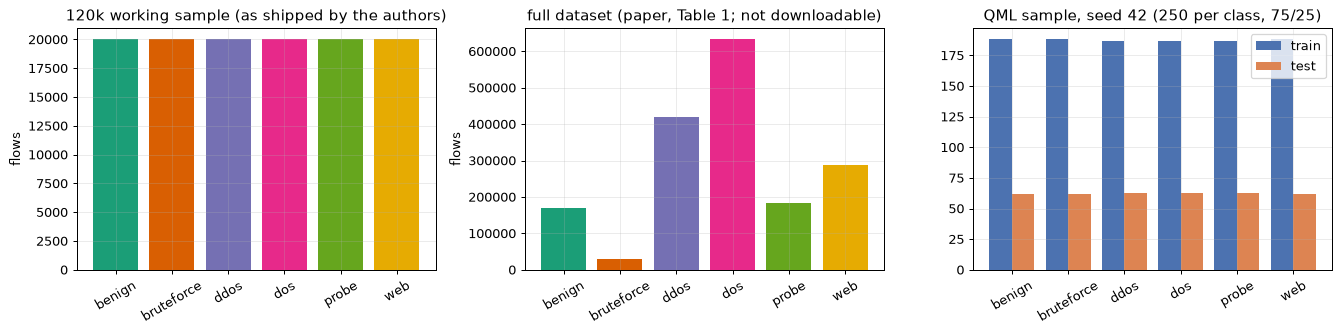

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
cnt = df["attack_category"].value_counts().reindex(CLASS_ORDER)
ax[0].bar(cnt.index, cnt.values, color=[CLASS_COLORS[c] for c in cnt.index])
ax[0].set_title("120k working sample (as shipped by the authors)"); ax[0].set_ylabel("flows")
full = pd.Series({"dos": 632507, "ddos": 420282, "web": 288304, "probe": 183293, "benign": 170865, "bruteforce": 28566}).reindex(CLASS_ORDER)
ax[1].bar(full.index, full.values, color=[CLASS_COLORS[c] for c in full.index])
ax[1].set_title("full dataset (paper, Table 1; not downloadable)"); ax[1].set_ylabel("flows")
q = pd.Series(S42["names_tr"]).value_counts().reindex(CLASS_ORDER)
qt = pd.Series(S42["names_te"]).value_counts().reindex(CLASS_ORDER)
w = 0.4; xs = np.arange(6)
ax[2].bar(xs - w/2, q.values, w, label="train", color="#4c72b0"); ax[2].bar(xs + w/2, qt.values, w, label="test", color="#dd8452")
ax[2].set_xticks(xs); ax[2].set_xticklabels(CLASS_ORDER); ax[2].legend()
ax[2].set_title("QML sample, seed 42 (250 per class, 75/25)")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### Real flows in two dimensions

Each point is one real network flow, coloured by its true attack family (six classes, not just binary).
First the raw PCA coordinates of the six qubit features (standardised and projected with a PCA fitted on the **training** flows only), then the same coordinates rescaled to [0, pi]
as the angle encoding does, and finally the first two *encoded angles themselves* (`dst_port`, `conn_state_enc`) that the circuit actually receives.

PCA explained variance ratio (2 components, train): [0.361 0.217]


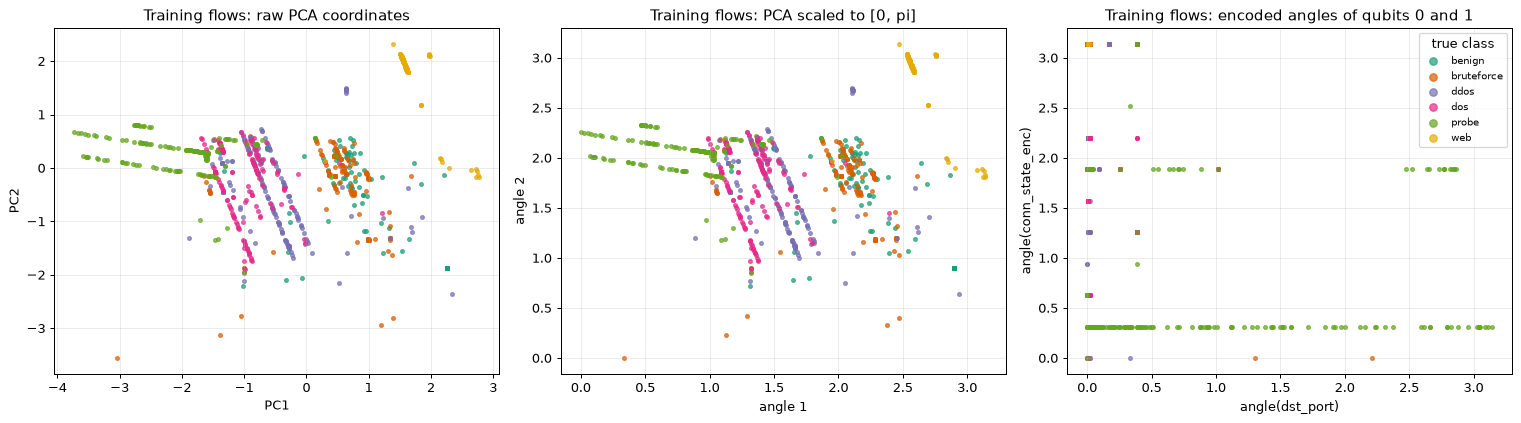

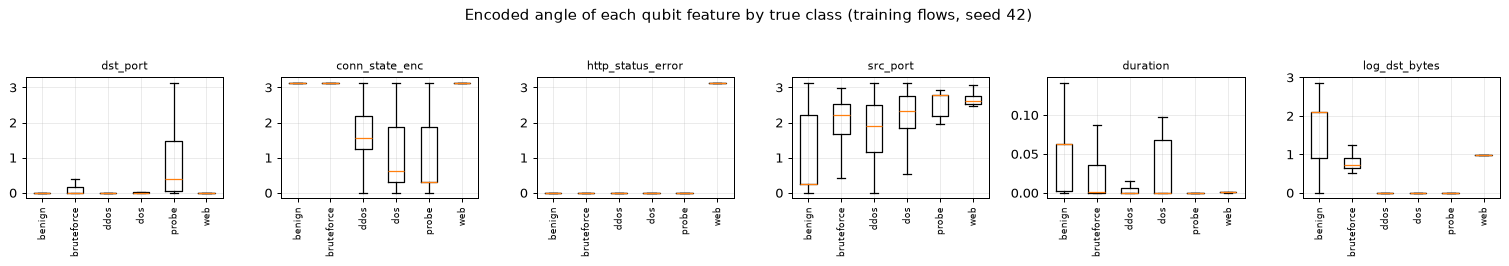

In [8]:
scaler_raw = StandardScaler().fit(S42["raw_tr"]); pca = PCA(n_components=2, random_state=SEED).fit(scaler_raw.transform(S42["raw_tr"]))
Ptr = pca.transform(scaler_raw.transform(S42["raw_tr"]))
mm = MinMaxScaler((0, np.pi)).fit(Ptr); Ptr_ang = mm.transform(Ptr)
print("PCA explained variance ratio (2 components, train):", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for c in CLASS_ORDER:
    m = S42["names_tr"] == c
    ax[0].scatter(Ptr[m, 0], Ptr[m, 1], s=9, alpha=0.7, c=CLASS_COLORS[c], label=c)
    ax[1].scatter(Ptr_ang[m, 0], Ptr_ang[m, 1], s=9, alpha=0.7, c=CLASS_COLORS[c], label=c)
    ax[2].scatter(S42["Xtr"][m, 0], S42["Xtr"][m, 1], s=9, alpha=0.7, c=CLASS_COLORS[c], label=c)
ax[0].set_title("Training flows: raw PCA coordinates"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[1].set_title("Training flows: PCA scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
ax[2].set_title("Training flows: encoded angles of qubits 0 and 1"); ax[2].set_xlabel("angle(dst_port)"); ax[2].set_ylabel("angle(conn_state_enc)")
ax[2].legend(markerscale=2, fontsize=8, title="true class")
plt.tight_layout(); plt.show()

# all six encoded angles per class (what the circuit really sees)
fig, ax = plt.subplots(1, 6, figsize=(17, 2.8))
for j, f in enumerate(QML_FEATURES):
    ax[j].boxplot([S42["Xtr"][S42["names_tr"] == c, j] for c in CLASS_ORDER], showfliers=False)
    ax[j].set_xticks(range(1, 7)); ax[j].set_xticklabels(CLASS_ORDER)
    ax[j].set_title(f, fontsize=9); ax[j].tick_params(axis="x", rotation=90, labelsize=7)
plt.suptitle("Encoded angle of each qubit feature by true class (training flows, seed 42)", y=1.04); plt.tight_layout(); plt.show()

## 3. Classical models on 120,000 flows (paper Table 2)

Five classical classifiers on the 15 selected features, 80/20 stratified split, multiclass and binary (attack = positive class).
Decision tree, random forest and gradient boosting use raw features, logistic regression and KNN use standardised features (scaler fitted on the training split).
The times are for batch training plus prediction, not per-flow latency (the paper says the same).
In `FAST_MODE` only 5,000 flows per class are used, so the numbers differ slightly from the paper's 20,000 per class.

Table 2 reproduction (120,000 flows, 80/20) computed in 1143 s


,Acc,F1-macro,Acc bin,F1 bin,Time (s)
Model,,,,,
Decision Tree,94.50,94.57,96.60,97.98,1.96
Random Forest,94.76,94.84,96.93,98.18,33.93
Gradient Boosting,94.59,94.66,96.45,97.89,940.19
Logistic Regression,80.56,80.54,93.81,96.41,11.45
KNN (k=5),93.53,93.62,96.20,97.73,8.92


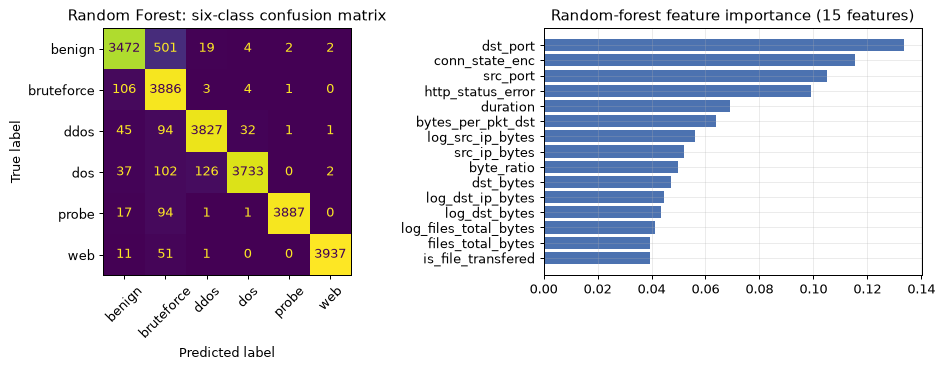

In [9]:
def run_classical(per_class, seed=SEED):
    d = df.groupby("attack_category", group_keys=False).sample(n=per_class, random_state=seed).reset_index(drop=True)
    X, ym, yb = d[FEATURES_15].to_numpy(float), d["label"].to_numpy(), d["label_bin"].to_numpy()
    Xtr, Xte, ymtr, ymte, ybtr, ybte = train_test_split(X, ym, yb, test_size=0.2, random_state=seed, stratify=ym)
    sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
    models = {
        "Decision Tree": (lambda: DecisionTreeClassifier(max_depth=15, random_state=seed), False),
        "Random Forest": (lambda: RandomForestClassifier(n_estimators=100, max_depth=15, random_state=seed, n_jobs=2), False),
        "Gradient Boosting": (lambda: GradientBoostingClassifier(n_estimators=100, max_depth=5, random_state=seed), False),
        "Logistic Regression": (lambda: LogisticRegression(max_iter=1000, random_state=seed), True),
        "KNN (k=5)": (lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=2), True),
    }
    rows, fitted = [], {}
    for name, (mk, scaled) in models.items():
        A, B = (Xtr_s, Xte_s) if scaled else (Xtr, Xte)
        t0 = time.time(); m = mk().fit(A, ymtr); pm = m.predict(B); dt = time.time() - t0
        mb = mk().fit(A, ybtr); pb = mb.predict(B)
        rows.append({"Model": name, "Acc": 100*accuracy_score(ymte, pm), "F1-macro": 100*f1_score(ymte, pm, average="macro"),
                     "Acc bin": 100*accuracy_score(ybte, pb), "F1 bin": 100*f1_score(ybte, pb), "Time (s)": dt})
        fitted[name] = (m, pm)
    return pd.DataFrame(rows).set_index("Model"), ymte, fitted

t0 = time.time()
table2, ymte_cls, fitted_cls = run_classical(CLASSICAL_PER_CLASS)
print(f"Table 2 reproduction ({6*CLASSICAL_PER_CLASS:,} flows, 80/20) computed in {time.time()-t0:.0f} s")
display(table2.round(2))

best = table2["F1-macro"].idxmax()
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(ymte_cls, fitted_cls[best][1], display_labels=CLASS_ORDER, ax=ax[0], colorbar=False, xticks_rotation=45)
ax[0].set_title(f"{best}: six-class confusion matrix"); ax[0].grid(False)
imp_best = pd.Series(fitted_cls["Random Forest"][0].feature_importances_, index=FEATURES_15).sort_values()
ax[1].barh(imp_best.index, imp_best.values, color="#4c72b0"); ax[1].set_title("Random-forest feature importance (15 features)")
plt.tight_layout(); plt.show()

## 4. The quantum feature map and the quantum kernel

**ZZFeatureMap, 6 qubits, 2 repetitions** (paper Eq. 1): per repetition, Hadamards, then `P(2 x_q)` on every qubit (the paper writes `R_z(2 x_q)`, which differs only by a global phase),
then for every neighbouring pair (q, q+1): `CNOT`, `P(2 (pi - x_q)(pi - x_{q+1}))` on the second qubit, `CNOT`. The kernel is the state fidelity
`K(a, b) = |<phi(a)|phi(b)>|^2` = `|0...0>` probability of the circuit `U(b)^dagger U(a)`.

We use three equivalent routes, and **assert that they agree**:

1. Qiskit: `FidelityStatevectorKernel(zz_feature_map(...))` inside `QSVC` (slow, pure Python loop over pairs),
2. Qiskit statevectors of the very same circuit, with the kernel formed by hand,
3. a vectorised NumPy evaluation of the same circuit (the feature map is `D(x) H D(x) H |0>` with a diagonal phase `D`), which is what the repeated experiments below use because it takes milliseconds instead of minutes.

The VQC is evaluated the same way: the trainable part is a fixed 64 x 64 unitary (taken from the Qiskit circuit with `Operator`) applied to the pre-computed feature-map states.

In [10]:
N = N_QUBITS; DIM = 2 ** N
IDX = np.arange(DIM)
ZBITS = ((IDX[:, None] >> np.arange(N)) & 1).astype(float)                    # bit i of the basis index = qubit i (Qiskit order)
PAIR_XOR = np.stack([(ZBITS[:, i] != ZBITS[:, i + 1]) for i in range(N - 1)], 1).astype(float)
_H1 = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
HAD = np.array([[1.0]])
for _ in range(N):
    HAD = np.kron(HAD, _H1)                                                    # H^{(x)n}

def zz_states(X, reps=2, scale=1.0):
    """Statevectors of zz_feature_map(N, reps, 'linear') for every row of X (angle scale = kernel bandwidth)."""
    X = np.atleast_2d(np.asarray(X, float)) * scale
    phase = 2 * X @ ZBITS.T                                                    # P(2 x_q) on every qubit
    phase = phase + (2 * (np.pi - X[:, :-1]) * (np.pi - X[:, 1:])) @ PAIR_XOR.T  # CNOT-P-CNOT on neighbours
    D = np.exp(1j * phase)
    psi = np.zeros((len(X), DIM), complex); psi[:, 0] = 1
    for _ in range(reps):
        psi = D * (psi @ HAD.T)
    return psi

def fidelity_kernel(A, B):
    return np.abs(A.conj() @ B.T) ** 2

def qkernel(Xa, Xb=None, reps=2, scale=1.0):
    A = zz_states(Xa, reps, scale)
    return fidelity_kernel(A, A if Xb is None else zz_states(Xb, reps, scale))

# ---- equivalence checks against Qiskit ----
fmap = zz_feature_map(N, reps=2, entanglement="linear")
Xchk = S42["Xtr"][:12]
sv_qiskit = np.array([Statevector(fmap.assign_parameters(x)).data for x in Xchk])
sv_np = zz_states(Xchk)
print("max | <qiskit|numpy> |^2 deviation from 1:", np.abs(np.abs(np.sum(sv_qiskit.conj() * sv_np, 1)) ** 2 - 1).max())
assert np.allclose(np.abs(np.sum(sv_qiskit.conj() * sv_np, 1)) ** 2, 1)
Kq = FidelityStatevectorKernel(feature_map=fmap).evaluate(Xchk, Xchk)
assert np.allclose(Kq, qkernel(Xchk), atol=1e-10) and np.allclose(Kq, fidelity_kernel(sv_qiskit, sv_qiskit), atol=1e-10)
print("FidelityStatevectorKernel == hand-made Qiskit fidelity kernel == NumPy kernel:  OK")

# ---- QSVC on a subset (Qiskit's own estimator) vs SVC on the precomputed NumPy kernel ----
n_sub_tr, n_sub_te = (150, 60) if FAST_MODE else (300, 100)
t0 = time.time()
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fmap), C=1.0).fit(S42["Xtr"][:n_sub_tr], S42["yb_tr"][:n_sub_tr])
pq = qsvc.predict(S42["Xte"][:n_sub_te]); t_q = time.time() - t0
svc_pre = SVC(kernel="precomputed", C=1.0).fit(qkernel(S42["Xtr"][:n_sub_tr]), S42["yb_tr"][:n_sub_tr])
pp = svc_pre.predict(qkernel(S42["Xte"][:n_sub_te], S42["Xtr"][:n_sub_tr]))
print(f"QSVC ({n_sub_tr} train / {n_sub_te} test): {t_q:.1f} s, acc {accuracy_score(S42['yb_te'][:n_sub_te], pq):.3f}; "
      f"identical predictions to the precomputed-kernel SVC: {bool((pq == pp).all())}")
assert (pq == pp).all()

# ---- classical QIK-SVM encoding (quantum-inspired, no circuit) ----
def qik_encode(X):
    return np.hstack([np.cos(X), np.sin(X), np.cos(2 * X), np.sin(2 * X)])
def qik_kernel(Xa, Xb, gamma=1.0):
    return rbf_kernel(qik_encode(Xa), qik_encode(Xb), gamma=gamma)

# ---- VQC circuit (paper Section 3.2): ZZFeatureMap(reps=1) + 2 x [Ry, Rz on every qubit + CNOT ring] ----
def build_vqc(n_layers=VQC_LAYERS):
    fm1 = zz_feature_map(N, reps=1, entanglement="linear", parameter_prefix="x")
    th = ParameterVector("theta", n_layers * N * 2)
    ans = QuantumCircuit(N, name="ansatz"); c = 0
    for _ in range(n_layers):
        for q in range(N):
            ans.ry(th[c], q); c += 1
            ans.rz(th[c], q); c += 1
        for q in range(N):
            ans.cx(q, (q + 1) % N)                      # CHOICE: ring of CNOTs q -> q+1 (mod 6)
    return fm1, ans, th, fm1.compose(ans)
fm1, ansatz, THETA, vqc_full = build_vqc()

def ansatz_unitary(theta):
    return Operator(ansatz.assign_parameters(dict(zip(THETA, theta)))).data

def vqc_p1(Phi, theta):
    """p(1|x) = (1 - <Z_0>)/2 = P(qubit 0 = 1), evaluated for every pre-computed feature state in Phi."""
    out = Phi @ ansatz_unitary(theta).T
    return (np.abs(out) ** 2) @ ZBITS[:, 0]

# equivalence of the fast VQC evaluation with the full Qiskit circuit
th0 = np.random.default_rng(1).uniform(0, 2 * np.pi, len(THETA)); xs = S42["Xtr"][:4]
for x in xs:
    bind = dict(zip(list(fm1.parameters), x)); bind.update(dict(zip(THETA, th0)))
    sv = Statevector(vqc_full.assign_parameters(bind))
    p_qiskit = sv.probabilities([0])[1]
    p_fast = vqc_p1(zz_states(x, reps=1), th0)[0]
    assert abs(p_qiskit - p_fast) < 1e-10
print("VQC: Qiskit full-circuit probability == fast evaluation:  OK")

max | <qiskit|numpy> |^2 deviation from 1: 4.884981308350689e-15
FidelityStatevectorKernel == hand-made Qiskit fidelity kernel == NumPy kernel:  OK


QSVC (300 train / 100 test): 9.9 s, acc 0.880; identical predictions to the precomputed-kernel SVC: True
VQC: Qiskit full-circuit probability == fast evaluation:  OK


## Quantum Circuit Architecture

All circuits below are the Qiskit objects that are executed (or, for the noisy study, transpiled onto the fake backends and then executed on Aer).
Drawings are produced from the decomposed circuits; qubit count, depth and the number of trainable parameters are printed under each.
Assumptions where the paper omits details: linear nearest-neighbour entanglement pairs for the ZZFeatureMap; the CNOT ring runs q0->q1, ..., q5->q0 after every rotation layer;
`P(2x)` is used instead of `R_z(2x)` (same kernel); the measurement is of qubit 0 in the Z basis (`p(1|x)` = probability that qubit 0 reads 1).
The QIK-SVM is classical and has no circuit.

QKSVM feature map U(x)   (6 data angles, 0 trainable): qubits=6, depth=25, parameters=6, gates={'u': 34, 'cx': 20}


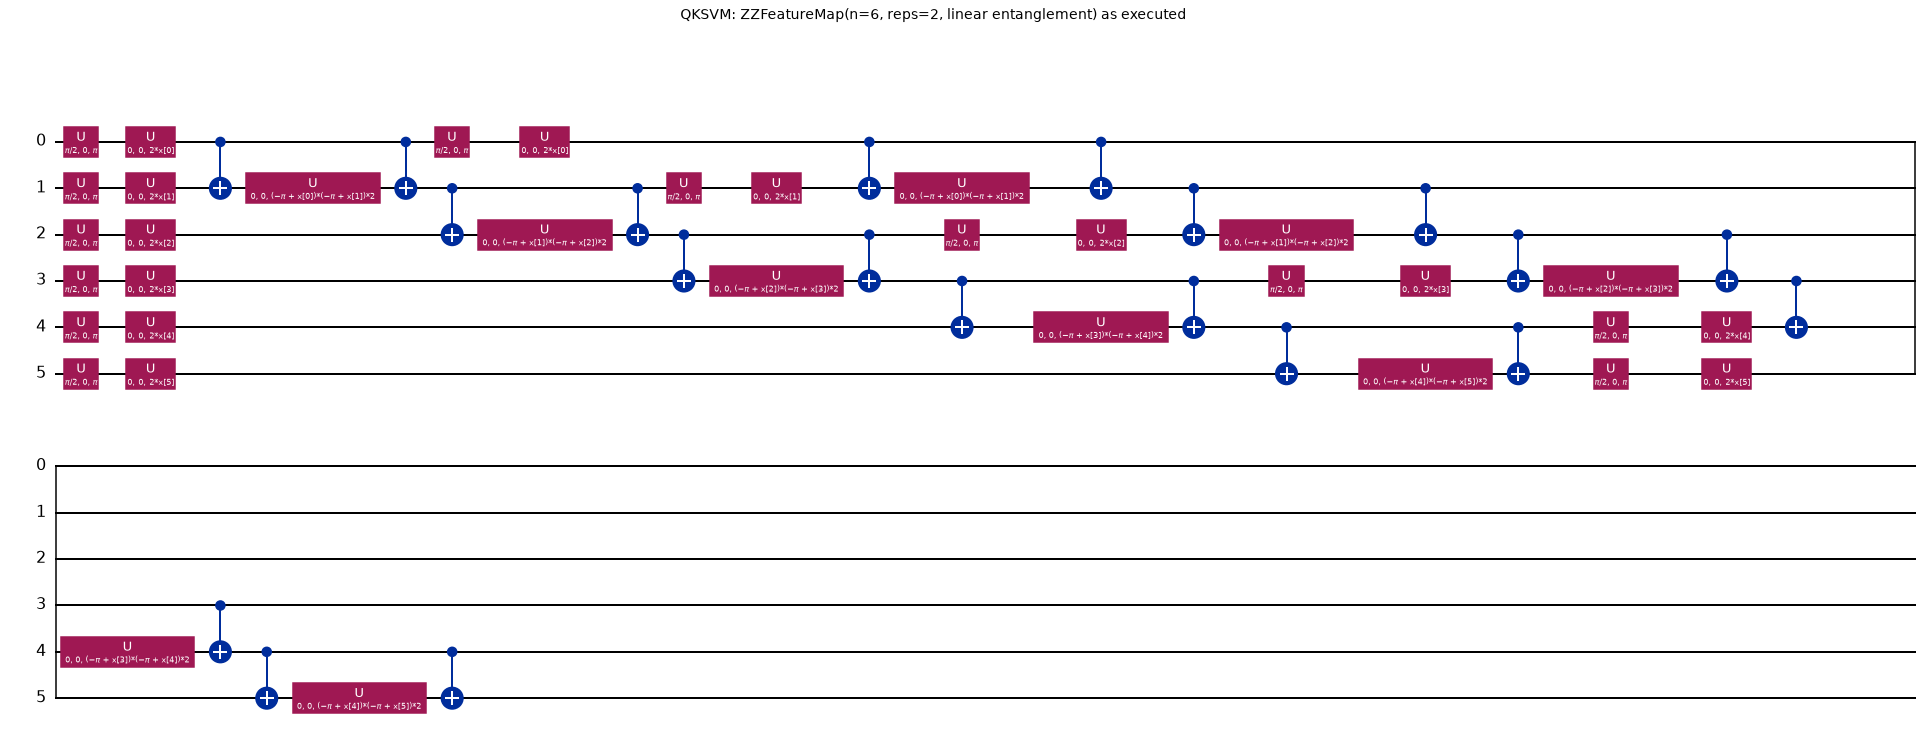

In [11]:
from IPython.display import display

def show_circuit(qc, title, **kw):
    fig = qc.draw("mpl", **kw)
    fig.suptitle(title, y=1.0, fontsize=11)
    display(fig)
    plt.close(fig)

def describe(name, qc):
    d = qc.decompose(reps=3)
    ops = dict(d.count_ops())
    print(f"{name}: qubits={d.num_qubits}, depth={d.depth()}, parameters={qc.num_parameters}, gates={ops}")

describe("QKSVM feature map U(x)   (6 data angles, 0 trainable)", fmap)
show_circuit(fmap.decompose(), "QKSVM: ZZFeatureMap(n=6, reps=2, linear entanglement) as executed", fold=40, scale=0.8)

Kernel circuit U(y)^dagger U(x) + measurement (12 data angles, 0 trainable): qubits=6, depth=51, parameters=12, gates={'u': 68, 'cx': 40, 'measure': 6}


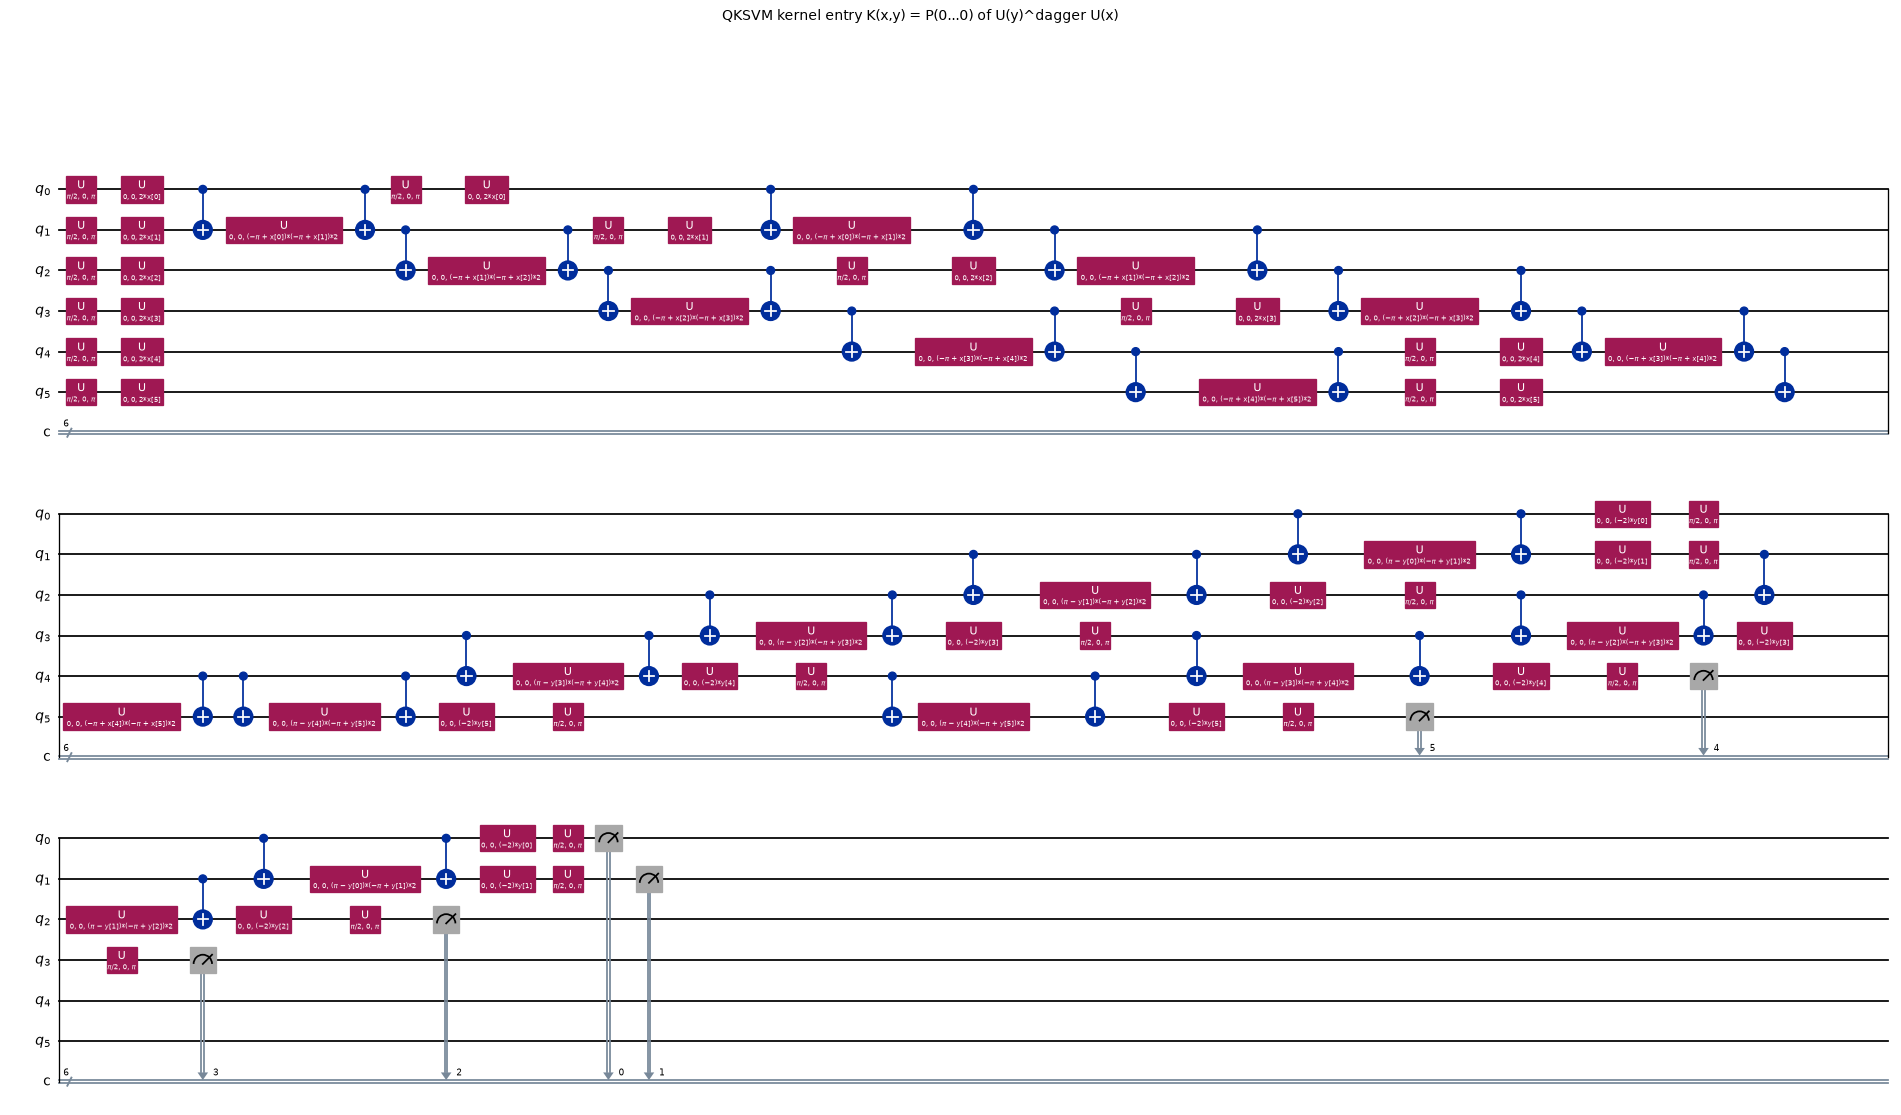

In [12]:
# kernel circuit actually evaluated on hardware-like simulators: U(x) followed by U(y)^dagger, then measure all qubits
def kernel_circuit(reps=2):
    fx = zz_feature_map(N, reps=reps, entanglement="linear", parameter_prefix="x")
    fy = zz_feature_map(N, reps=reps, entanglement="linear", parameter_prefix="y")
    qc = QuantumCircuit(N, N)
    qc.compose(fx, inplace=True); qc.compose(fy.inverse(), inplace=True)
    qc.measure(range(N), range(N))
    return qc, list(fx.parameters), list(fy.parameters)
kcirc, XPARAMS, YPARAMS = kernel_circuit()
describe("Kernel circuit U(y)^dagger U(x) + measurement (12 data angles, 0 trainable)", kcirc)
show_circuit(kcirc.decompose(), "QKSVM kernel entry K(x,y) = P(0...0) of U(y)^dagger U(x)", fold=45, scale=0.7)

VQC (ZZFeatureMap reps=1 + 2 layers Ry/Rz + CNOT ring; 6 data angles + 24 trainable): qubits=6, depth=30, parameters=30, gates={'u': 41, 'cx': 22}
trainable parameters: 24 | readout: <Z_0>, p(1|x) = (1 - <Z_0>)/2


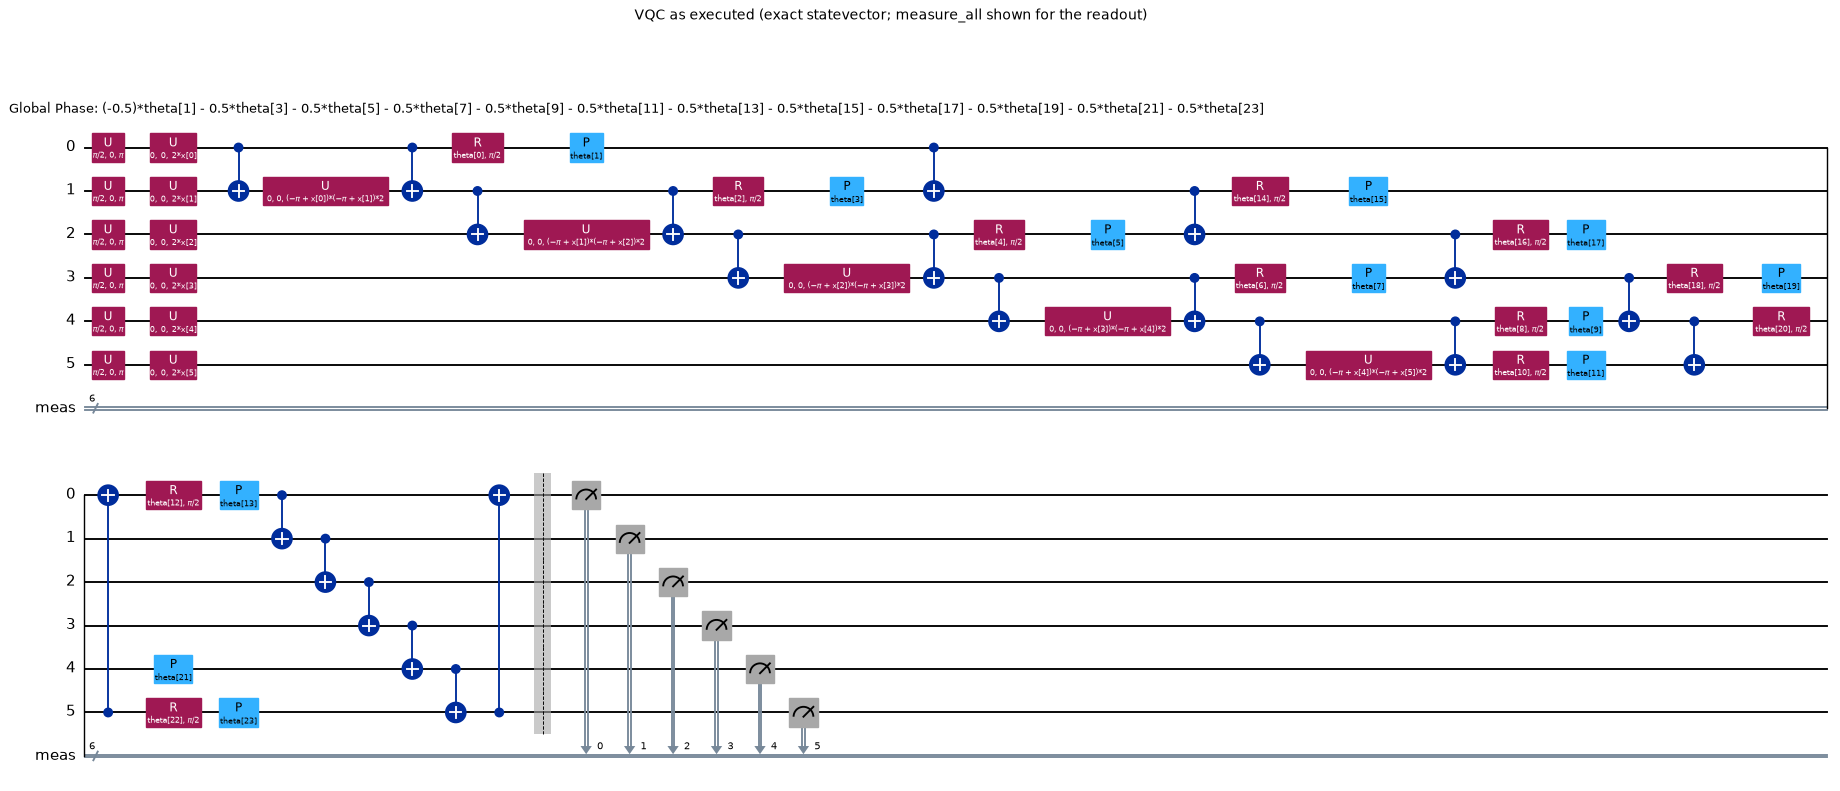

In [13]:
describe(f"VQC (ZZFeatureMap reps=1 + {VQC_LAYERS} layers Ry/Rz + CNOT ring; 6 data angles + {len(THETA)} trainable)", vqc_full)
print("trainable parameters:", len(THETA), "| readout: <Z_0>, p(1|x) = (1 - <Z_0>)/2")
vqc_draw = vqc_full.copy(); vqc_draw.measure_all()
show_circuit(vqc_draw.decompose(), "VQC as executed (exact statevector; measure_all shown for the readout)", fold=40, scale=0.75)

FakeKyoto stored ECR error: min 1.00, max 1.00  -> not usable; FakeSherbrooke used instead


ibm_brisbane  (fake_brisbane): layout [9, 10, 11, 12, 17, 30] | physical qubits used [9, 10, 11, 12, 17, 30] | depth 133 | 2-qubit gates 38 | ops {'rz': 189, 'sx': 77, 'ecr': 38, 'x': 18, 'measure': 6}


ibm_sherbrooke (fake_sherbrooke): layout [58, 59, 60, 61, 62, 72] | physical qubits used [58, 59, 60, 61, 62, 72] | depth 150 | 2-qubit gates 38 | ops {'rz': 209, 'sx': 98, 'ecr': 38, 'x': 11, 'measure': 6}


ibm_nairobi   (fake_nairobi): layout None | physical qubits used [1, 2, 3, 4, 5, 6] | depth 77 | 2-qubit gates 44 | ops {'rz': 92, 'cx': 44, 'sx': 24, 'measure': 6}


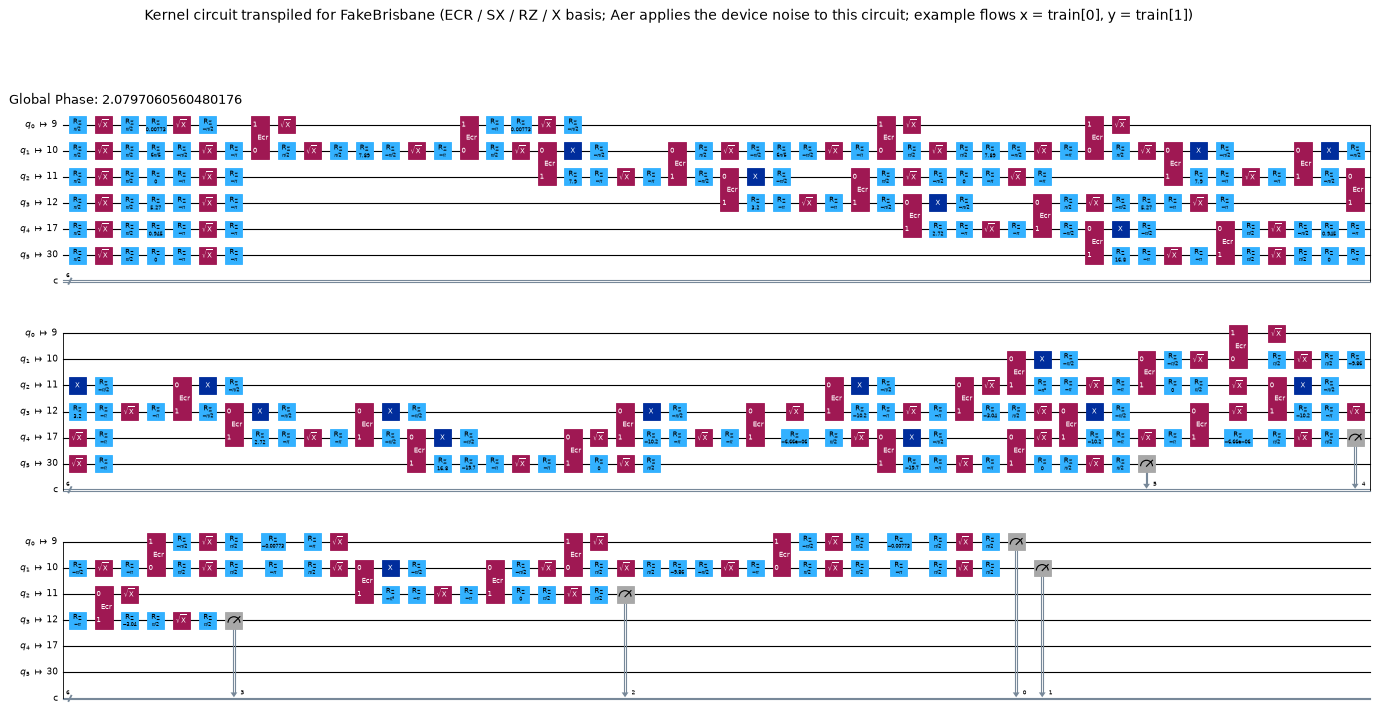

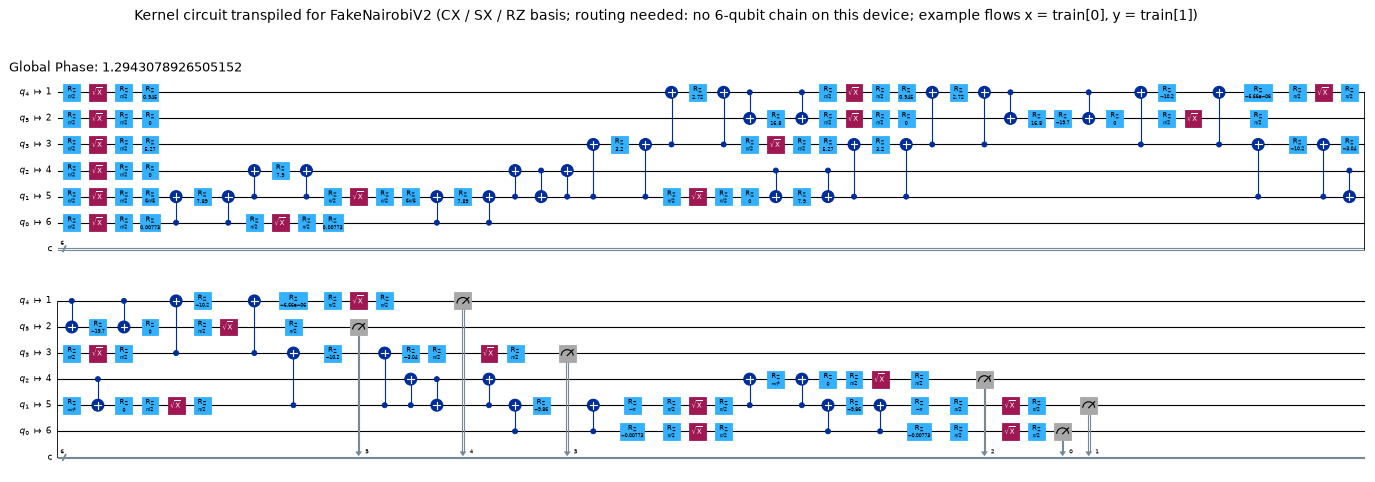

In [14]:
# the same kernel circuit transpiled onto the noisy fake backends used in section 8 (what Aer really runs there)
def best_path(be, n):
    """Lowest-error simple path of n qubits in the coupling map (None if the device has no such path)."""
    tgt = be.target
    twoq = next(g for g in ("ecr", "cx", "cz") if g in tgt.operation_names)
    err = {}
    for (a, b), p in tgt[twoq].items():
        e = p.error if (p is not None and p.error is not None) else 1.0
        if e < 0.5:                                                         # ignore dead links
            err[(a, b)] = e
    adj = {}
    for (a, b) in err:
        adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    cost = lambda a, b: min(err.get((a, b), 9), err.get((b, a), 9))
    best = [None, 1e9]
    def dfs(path, c):
        if c >= best[1]: return
        if len(path) == n: best[0], best[1] = list(path), c; return
        for nb in adj.get(path[-1], ()):
            if nb not in path:
                path.append(nb); dfs(path, c + cost(path[-2], nb)); path.pop()
    for s in adj: dfs([s], 0.0)
    return best[0]

def bind_example(tc):
    """Bind two real training flows so that the gate labels are short numbers (drawing only)."""
    vals = dict(zip(XPARAMS, S42["Xtr"][0])); vals.update(dict(zip(YPARAMS, S42["Xtr"][1])))
    return tc.assign_parameters(vals)

# CHOICE: the stored FakeKyoto calibration snapshot has an ECR error of exactly 1.0 on every link (a fully depolarised device,
# kernel diagonal ~ 1/64), so it is useless as a noise model; FakeSherbrooke (same Eagle family, 2023-24) stands in for ibm_kyoto.
_ek = [v.error for v in FakeKyoto().target["ecr"].values()]
print(f"FakeKyoto stored ECR error: min {min(_ek):.2f}, max {max(_ek):.2f}  -> not usable; FakeSherbrooke used instead")
FAKE_BACKENDS = {"ibm_brisbane": FakeBrisbane, "ibm_sherbrooke": FakeSherbrooke, "ibm_nairobi": FakeNairobiV2}
TRANSPILED, NOISE_MODELS = {}, {}
for name, cls in FAKE_BACKENDS.items():
    be = cls()
    layout = best_path(be, N)                                              # CHOICE: lowest-error 6-qubit chain (None -> transpiler decides)
    tc = transpile(kcirc, be, initial_layout=layout, optimization_level=1, seed_transpiler=SEED)
    TRANSPILED[name] = tc; NOISE_MODELS[name] = NoiseModel.from_backend(be)
    used = sorted({tc.find_bit(q).index for inst in tc.data for q in inst.qubits})
    print(f"{name:13s} ({be.name}): layout {layout} | physical qubits used {used} | depth {tc.depth()} | "
          f"2-qubit gates {sum(v for k, v in tc.count_ops().items() if k in ('ecr','cx','cz'))} | ops {dict(tc.count_ops())}")
show_circuit(bind_example(TRANSPILED["ibm_brisbane"]), "Kernel circuit transpiled for FakeBrisbane (ECR / SX / RZ / X basis; Aer applies the device noise to this circuit; example flows x = train[0], y = train[1])", idle_wires=False, fold=50, scale=0.45)
show_circuit(bind_example(TRANSPILED["ibm_nairobi"]), "Kernel circuit transpiled for FakeNairobiV2 (CX / SX / RZ basis; routing needed: no 6-qubit chain on this device; example flows x = train[0], y = train[1])", idle_wires=False, fold=50, scale=0.45)

## 5. QKSVM vs VQC vs QIK-SVM vs classical models (paper Table 3 and paired test)

For each seed 42, 43, ..., 51 we draw 250 flows per class (1,500 in total), split 75/25 and train:

* **binary** (attack = positive): QKSVM (ZZ kernel, `SVC(kernel="precomputed")`), SVM-RBF, logistic regression, a random forest (extra), the majority-class baseline and the **VQC** (first `R_VQC` seeds only, as in the paper, because COBYLA is expensive);
* **six-class**: QIK-SVM, random forest (the paper's multiclass classical reference), QKSVM and SVM-RBF (extras), the majority-class baseline.

An extra row, **QKSVM-bw**, chooses the kernel angle scale in {0.25, 0.5, 1, 2} on a validation part of the training data only (the paper uses scale 1).
The binary test set is imbalanced (5 attack classes against 1 benign class = 83.3 % attacks), so F1-macro is reported next to accuracy.

In [15]:
def fit_eval(clf, A, ytr, B, yte):
    t0 = time.time(); clf.fit(A, ytr); p = clf.predict(B); dt = time.time() - t0
    return p, dt

def metrics(y, p):
    return 100 * accuracy_score(y, p), 100 * f1_score(y, p, average="macro")

def pick_scale(Xtr, ytr, seed, scales=(0.25, 0.5, 1.0, 2.0)):
    """Kernel angle scale (bandwidth) chosen on a validation split of the TRAINING data only."""
    a, b = train_test_split(np.arange(len(Xtr)), test_size=0.25, random_state=seed, stratify=ytr)
    best, best_acc = 1.0, -1
    for s in scales:
        K = qkernel(Xtr[a], scale=s)
        acc = accuracy_score(ytr[b], SVC(kernel="precomputed", C=1.0).fit(K, ytr[a]).predict(qkernel(Xtr[b], Xtr[a], scale=s)))
        if acc > best_acc + 1e-12: best, best_acc = s, acc
    return best

records = []          # (model, task, seed, acc, f1_macro, seconds)
vqc_log = []          # per VQC run
kept = {}
for rep in range(R_MAIN):
    seed = SEED + rep
    S = S42 if rep == 0 else make_qml_sample(seed)
    Xtr, Xte, ybtr, ybte, ymtr, ymte = S["Xtr"], S["Xte"], S["yb_tr"], S["yb_te"], S["ym_tr"], S["ym_te"]
    rec = lambda m, t, y, p, dt: records.append((m, t, seed, *metrics(y, p), dt))

    t0 = time.time(); Ktr = qkernel(Xtr); Kte = qkernel(Xte, Xtr); tk = time.time() - t0     # quantum kernel matrices
    p, dt = fit_eval(SVC(kernel="precomputed", C=1.0), Ktr, ybtr, Kte, ybte); rec("QKSVM", "binary", ybte, p, dt + tk)
    if rep == 0: kept["qk_pred"], kept["qk_yte"] = p, ybte
    p, dt = fit_eval(SVC(kernel="precomputed", C=1.0), Ktr, ymtr, Kte, ymte); rec("QKSVM", "multi", ymte, p, dt + tk)
    s_best = pick_scale(Xtr, ybtr, seed)
    p, dt = fit_eval(SVC(kernel="precomputed", C=1.0), qkernel(Xtr, scale=s_best), ybtr, qkernel(Xte, Xtr, scale=s_best), ybte)
    rec("QKSVM-bw", "binary", ybte, p, dt); kept.setdefault("scales", []).append(s_best)

    p, dt = fit_eval(SVC(kernel="rbf"), Xtr, ybtr, Xte, ybte); rec("SVM-RBF", "binary", ybte, p, dt)
    p, dt = fit_eval(SVC(kernel="rbf"), Xtr, ymtr, Xte, ymte); rec("SVM-RBF", "multi", ymte, p, dt)
    p, dt = fit_eval(LogisticRegression(max_iter=500, random_state=seed), Xtr, ybtr, Xte, ybte); rec("LR", "binary", ybte, p, dt)
    p, dt = fit_eval(RandomForestClassifier(n_estimators=50, max_depth=8, random_state=seed, n_jobs=2), Xtr, ybtr, Xte, ybte); rec("RF", "binary", ybte, p, dt)
    p, dt = fit_eval(RandomForestClassifier(n_estimators=50, max_depth=8, random_state=seed, n_jobs=2), Xtr, ymtr, Xte, ymte); rec("RF", "multi", ymte, p, dt)
    p, dt = fit_eval(SVC(kernel="precomputed", C=1.0), qik_kernel(Xtr, Xtr), ymtr, qik_kernel(Xte, Xtr), ymte); rec("QIK-SVM", "multi", ymte, p, dt)
    if rep == 0: kept["qik_pred"], kept["qik_yte"] = p, ymte
    p, dt = fit_eval(DummyClassifier(strategy="most_frequent"), Xtr, ybtr, Xte, ybte); rec("Majority", "binary", ybte, p, dt)
    p, dt = fit_eval(DummyClassifier(strategy="most_frequent"), Xtr, ymtr, Xte, ymte); rec("Majority", "multi", ymte, p, dt)

    if rep < R_VQC:                                                                   # ---- VQC ----
        rng = np.random.default_rng(seed)
        idx = rng.choice(len(Xtr), N_VQC_TRAIN, replace=False)
        Phi_vqc = zz_states(Xtr[idx], reps=1); yv = ybtr[idx]
        theta0 = rng.uniform(0, 2 * np.pi, len(THETA)); history = []
        def loss(theta):
            p1 = np.clip(vqc_p1(Phi_vqc, theta), 1e-7, 1 - 1e-7)
            val = -np.mean(yv * np.log(p1) + (1 - yv) * np.log(1 - p1)); history.append(val); return val
        t0 = time.time()
        res = minimize(loss, theta0, method="COBYLA", options={"maxiter": VQC_MAXITER, "rhobeg": VQC_RHOBEG})
        pv = (vqc_p1(zz_states(Xte, reps=1), res.x) >= 0.5).astype(int); dt = time.time() - t0
        rec("VQC", "binary", ybte, pv, dt)
        vqc_log.append(dict(seed=seed, success=bool(res.success), nfev=int(res.nfev), loss0=history[0], loss_final=history[-1],
                            acc=100 * accuracy_score(ybte, pv), history=history, frac_pred_attack=float(pv.mean())))
        if rep == 0: kept["vqc_pred"], kept["vqc_yte"] = pv, ybte
    print(f"seed {seed} done")

R = pd.DataFrame(records, columns=["model", "task", "seed", "acc", "f1_macro", "seconds"])
def ms(x): return f"{x.mean():.1f} +- {x.std(ddof=0):.1f}"
table3 = R.groupby(["task", "model"]).agg(runs=("seed", "count"), Acc=("acc", ms), F1_macro=("f1_macro", ms), seconds=("seconds", "mean")).round(2)
display(table3)
print("angle scales picked on validation data (QKSVM-bw):", kept["scales"])

seed 42 done


seed 43 done


seed 44 done


seed 45 done


seed 46 done


...

seed 49 done


seed 50 done


seed 51 done


runs          Acc     F1_macro  seconds
task   model                                            
binary LR          10  92.7 +- 1.2  85.2 +- 2.8     0.05
       Majority    10  83.3 +- 0.1  45.4 +- 0.0     0.00
       QKSVM       10  94.0 +- 0.9  87.6 +- 2.2     0.22
       QKSVM-bw    10  93.8 +- 0.9  87.1 +- 2.2     0.05
       RF          10  94.7 +- 0.7  89.6 +- 1.4     0.52
       SVM-RBF     10  93.3 +- 1.0  85.7 +- 2.7     0.07
       VQC          5  68.4 +- 4.0  57.5 +- 8.8     3.30
multi  Majority    10  16.5 +- 0.0   4.7 +- 0.0     0.00
       QIK-SVM     10  84.7 +- 1.4  84.5 +- 1.5     0.10
       QKSVM       10  85.0 +- 1.6  84.9 +- 1.6     0.28
       RF          10  89.7 +- 1.3  89.7 +- 1.3     0.52
       SVM-RBF     10  75.0 +- 3.1  75.1 +- 3.1     0.16

angle scales picked on validation data (QKSVM-bw): [2.0, 2.0, 0.25, 0.5, 0.25, 0.25, 0.25, 2.0, 1.0, 0.5]


QKSVM better than SVM-RBF in 9/10 resamplings (1 ties); mean gain +0.67 +- 0.50 pp
QKSVM with validation-tuned bandwidth vs SVM-RBF: better in 6/10, mean gain +0.48 pp


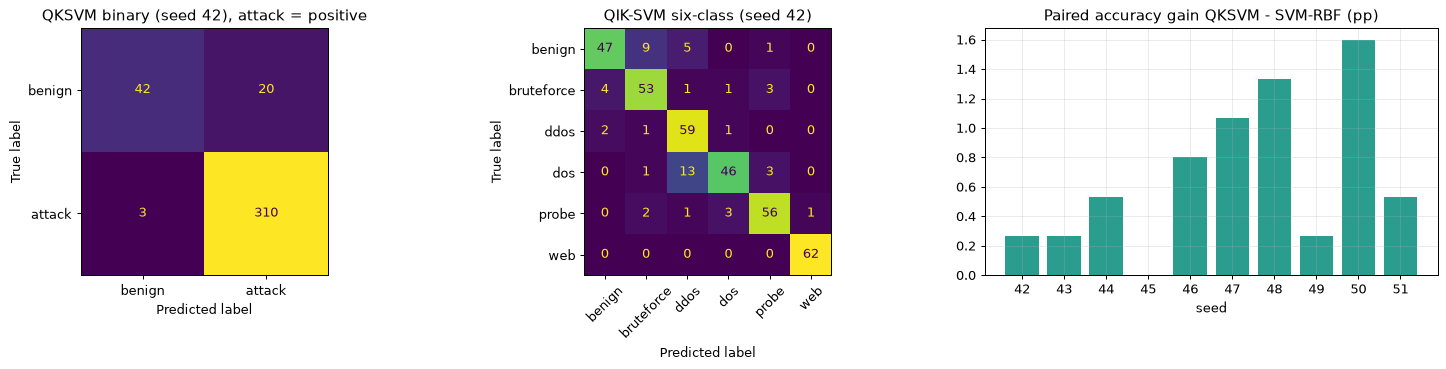

In [16]:
# paired comparison QKSVM vs SVM-RBF (binary), same resamplings
pa = R[(R.model == "QKSVM") & (R.task == "binary")].set_index("seed")["acc"]
pb = R[(R.model == "SVM-RBF") & (R.task == "binary")].set_index("seed")["acc"]
gain = pa - pb
wins = int((gain > 1e-9).sum()); ties = int((gain.abs() <= 1e-9).sum())
print(f"QKSVM better than SVM-RBF in {wins}/{len(gain)} resamplings ({ties} ties); mean gain {gain.mean():+.2f} +- {gain.std(ddof=0):.2f} pp")
pc = R[(R.model == "QKSVM-bw") & (R.task == "binary")].set_index("seed")["acc"]
print(f"QKSVM with validation-tuned bandwidth vs SVM-RBF: better in {int(((pc - pb) > 1e-9).sum())}/{len(pc)}, mean gain {(pc - pb).mean():+.2f} pp")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ConfusionMatrixDisplay.from_predictions(kept["qk_yte"], kept["qk_pred"], display_labels=["benign", "attack"], ax=ax[0], colorbar=False)
ax[0].set_title("QKSVM binary (seed 42), attack = positive"); ax[0].grid(False)
ConfusionMatrixDisplay.from_predictions(kept["qik_yte"], kept["qik_pred"], display_labels=CLASS_ORDER, ax=ax[1], colorbar=False, xticks_rotation=45)
ax[1].set_title("QIK-SVM six-class (seed 42)"); ax[1].grid(False)
ax[2].bar(gain.index.astype(str), gain.values, color=np.where(gain.values > 0, "#2a9d8f", "#e76f51"))
ax[2].axhline(0, c="k", lw=0.8); ax[2].set_title("Paired accuracy gain QKSVM - SVM-RBF (pp)"); ax[2].set_xlabel("seed")
plt.tight_layout(); plt.show()

VQC runs:
 seed  success  nfev  loss0  loss_final    acc  frac_pred_attack
   42    False   100  0.721       0.572 75.200             0.683
   43    False   100  0.720       0.546 65.067             0.557
   44    False   100  0.712       0.552 65.867             0.813
   45    False   100  0.743       0.555 70.933             0.611
   46    False   100  0.692       0.565 65.067             0.595
VQC accuracy 68.4 +- 4.0 % vs majority baseline 83.3 %  ->  below baseline in 5/5 runs; COBYLA reported success in 0/5 runs


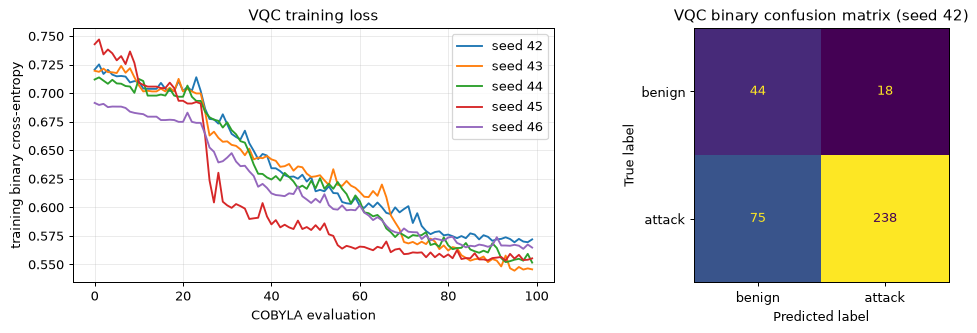

In [17]:
# VQC: loss curves and the verdict on convergence
print("VQC runs:")
print(pd.DataFrame([{k: v for k, v in d.items() if k != "history"} for d in vqc_log]).round(3).to_string(index=False))
maj_bin = R[(R.model == "Majority") & (R.task == "binary")]["acc"].mean()
vqc_acc = R[(R.model == "VQC")]["acc"]
print(f"VQC accuracy {ms(vqc_acc)} % vs majority baseline {maj_bin:.1f} %  ->  below baseline in "
      f"{int((vqc_acc < maj_bin - 1e-9).sum())}/{len(vqc_acc)} runs; COBYLA reported success in {sum(d['success'] for d in vqc_log)}/{len(vqc_log)} runs")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for d in vqc_log: ax[0].plot(d["history"], label=f"seed {d['seed']}")
ax[0].set_xlabel("COBYLA evaluation"); ax[0].set_ylabel("training binary cross-entropy"); ax[0].set_title("VQC training loss"); ax[0].legend()
ConfusionMatrixDisplay.from_predictions(kept["vqc_yte"], kept["vqc_pred"], display_labels=["benign", "attack"], ax=ax[1], colorbar=False)
ax[1].set_title("VQC binary confusion matrix (seed 42)"); ax[1].grid(False)
plt.tight_layout(); plt.show()

## 6. Few-sample regime (learning curve)

The paper reports that with very few training flows the quantum kernel is more stable than the RBF SVM (N = 30: 93.2 +- 0.7 % against 89.7 +- 4.3 %),
that the gap shrinks to less than 0.3 pp at N = 80 and that SVM-RBF is slightly ahead at N = 120. Training subsets are drawn from the 1,125 training flows of each resampling
(binary task, test set = the 375 test flows; `R_CURVE` resamplings).

,QKSVM mean,QKSVM std,SVM-RBF mean,SVM-RBF std,gain (pp)
N train,,,,,
30,91.71,3.03,88.24,3.79,3.47
50,92.67,0.95,90.08,3.73,2.59
80,92.69,1.11,92.35,0.98,0.35
120,92.80,0.93,92.43,0.77,0.37
180,92.88,0.94,92.40,0.93,0.48
250,92.69,0.97,92.51,0.97,0.19


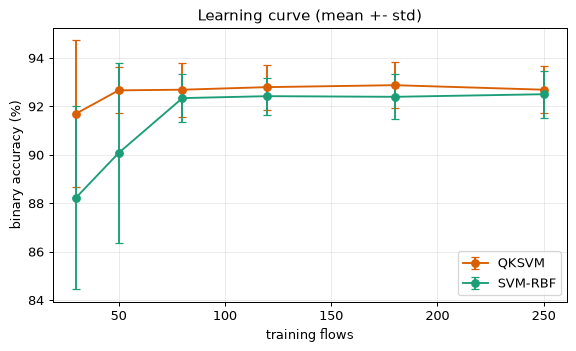

In [18]:
curve = {n: {"qk": [], "rbf": []} for n in CURVE_SIZES}
for rep in range(R_CURVE):
    seed = SEED + 100 + rep
    S = make_qml_sample(seed); rng = np.random.default_rng(seed)
    for n in CURVE_SIZES:
        idx = rng.choice(len(S["Xtr"]), n, replace=False)
        Xn, yn = S["Xtr"][idx], S["yb_tr"][idx]
        if len(np.unique(yn)) < 2:
            continue
        qk = SVC(kernel="precomputed", C=1.0).fit(qkernel(Xn), yn).predict(qkernel(S["Xte"], Xn))
        rb = SVC(kernel="rbf").fit(Xn, yn).predict(S["Xte"])
        curve[n]["qk"].append(100 * accuracy_score(S["yb_te"], qk)); curve[n]["rbf"].append(100 * accuracy_score(S["yb_te"], rb))
cdf = pd.DataFrame({n: {"QKSVM mean": np.mean(v["qk"]), "QKSVM std": np.std(v["qk"]), "SVM-RBF mean": np.mean(v["rbf"]), "SVM-RBF std": np.std(v["rbf"]),
                        "gain (pp)": np.mean(v["qk"]) - np.mean(v["rbf"])} for n, v in curve.items()}).T.round(2)
cdf.index.name = "N train"
display(cdf)
fig, ax = plt.subplots(figsize=(6.5, 4))
for key, lab, col in (("qk", "QKSVM", "#d95f02"), ("rbf", "SVM-RBF", "#1b9e77")):
    m = np.array([np.mean(curve[n][key]) for n in CURVE_SIZES]); s = np.array([np.std(curve[n][key]) for n in CURVE_SIZES])
    ax.errorbar(CURVE_SIZES, m, yerr=s, marker="o", capsize=3, label=lab, color=col)
ax.set_xlabel("training flows"); ax.set_ylabel("binary accuracy (%)"); ax.set_title("Learning curve (mean +- std)"); ax.legend()
plt.tight_layout(); plt.show()

## 7. NISQ noise sensitivity with the paper's heuristic channels (paper Section 3.3, Table 4)

The paper does not re-simulate the circuit under noise. It perturbs the *kernel matrix* with four closed-form channels (n = 6 qubits, d = 20 effective gate layers):

* depolarising: `K -> a K + (1 - a) / 2^n`, `a = (1 - 4p/3)^d`
* dephasing (T2): `K_ij -> exp(-p d) K_ij` for `i != j`
* amplitude damping (T1): `K -> f K + (1 - f) / 2^n`, `f = (1 - gamma/2)^d`
* shot noise: `K_ij ~ N(K_ij, K_ij (1 - K_ij) / N_shots)`

Four scenarios (three IBM backends and a "noisy extreme" one) apply all four channels together. Baseline: `R_NOISE = 8` resamplings of 600 flows (100 per class), 75/25 split, **no noise at all**.
We additionally apply each channel alone at the "noisy extreme" level, to check the claim that dephasing is the most damaging single channel, and sweep the dephasing probability p from 0 to 0.05.

**Two variants are run, because they behave very differently.**
All four channels are (nearly) affine maps of the kernel entries. The SVM is trained on the noisy training Gram matrix (unit diagonal) and applied to a *rectangular* test-versus-train kernel.

* **[A] formulas as printed.** The channels are applied to every kernel entry; the unit diagonal is restored only for the square training Gram matrix.
* **[B] the authors' public script.** In addition, the script calls `fill_diagonal(K, 1.0)` on the *rectangular* test kernel, which sets the similarity between test flow i and training flow i to 1, two unrelated flows declared identical. This is not a physical noise effect, but it is what produces the degradation of Table 4 (we show that below).

In [19]:
UNIFORM = 1.0 / DIM
def ch_depol(K, p, d=N_GATES_EFFECTIVE):
    a = (1 - 4 * p / 3) ** d
    return a * K + (1 - a) * UNIFORM
def ch_dephase(K, p, d=N_GATES_EFFECTIVE):
    return np.exp(-p * d) * K
def ch_ampdamp(K, gamma, d=N_GATES_EFFECTIVE):
    f = (1 - gamma / 2) ** d
    return f * K + (1 - f) * UNIFORM
def ch_shot(K, shots, rng):
    return K + rng.normal(0, np.sqrt(np.clip(K * (1 - K), 0, 1) / shots))
def finish(Kn, square, authors_quirk=False):
    Kn = np.clip(Kn, 0, 1)
    if square:                                   # symmetric Gram matrix of the training set, unit diagonal
        Kn = (Kn + Kn.T) / 2; np.fill_diagonal(Kn, 1.0)
    elif authors_quirk:                          # variant B: the authors' script also does this on the RECTANGULAR test kernel,
        np.fill_diagonal(Kn, 1.0)                # i.e. it declares test flow i and training flow i identical (not a physical effect)
    return Kn

# parameters of the four scenarios: taken from the authors' public script (CHOICE)
BACKEND_NOISE = {
    "ibm_brisbane (2024)": dict(depol=0.001, dephase=1 - np.exp(-T_GATE / 300), amp=1 - np.exp(-T_GATE / 400), shots=4096),
    "ibm_kyoto (2023)":    dict(depol=0.003, dephase=1 - np.exp(-T_GATE / 150), amp=1 - np.exp(-T_GATE / 200), shots=4096),
    "ibm_nairobi (2022)":  dict(depol=0.008, dephase=1 - np.exp(-T_GATE / 80),  amp=1 - np.exp(-T_GATE / 100), shots=1024),
    "Noisy extreme":       dict(depol=0.02,  dephase=1 - np.exp(-T_GATE / 20),  amp=1 - np.exp(-T_GATE / 30),  shots=512),
}
def apply_noise(K, par, rng, square, only=None, quirk=False):
    Kn = K.copy()
    if only in (None, "depol"):   Kn = ch_depol(Kn, par["depol"])
    if only in (None, "dephase"): Kn = ch_dephase(Kn, par["dephase"])
    if only in (None, "amp"):     Kn = ch_ampdamp(Kn, par["amp"])
    if only in (None, "shot"):    Kn = ch_shot(np.clip(Kn, 0, 1), par["shots"], rng)
    return finish(Kn, square, authors_quirk=quirk)
print(pd.DataFrame(BACKEND_NOISE).T.round(5))

                     depol  dephase      amp   shots
ibm_brisbane (2024)  0.001  0.00033  0.00025  4096.0
ibm_kyoto (2023)     0.003  0.00067  0.00050  4096.0
ibm_nairobi (2022)   0.008  0.00125  0.00100  1024.0
Noisy extreme        0.020  0.00499  0.00333   512.0


,Acc bin,delta bin (pp),Acc multi,delta multi (pp)
Scenario,,,,
No noise,92.67 +- 1.89,-,82.25 +- 4.90,-
[A] ibm_brisbane (2024),92.67 +- 1.63,+0.00,82.25 +- 4.98,+0.00
[A] ibm_kyoto (2023),92.67 +- 1.63,+0.00,82.25 +- 4.98,+0.00
[A] ibm_nairobi (2022),92.75 +- 1.75,+0.08,82.00 +- 4.91,-0.25
[A] Noisy extreme,92.67 +- 1.37,+0.00,81.42 +- 4.74,-0.83
[B] ibm_brisbane (2024),91.42 +- 2.15,-1.25,79.83 +- 4.51,-2.42
[B] ibm_kyoto (2023),90.75 +- 1.68,-1.92,78.92 +- 4.20,-3.33
[B] ibm_nairobi (2022),90.67 +- 1.29,-2.00,77.58 +- 3.89,-4.67
[B] Noisy extreme,89.75 +- 1.15,-2.92,73.83 +- 3.94,-8.42


[A] single channels at the 'noisy extreme' level, formulas as printed (binary accuracy, change vs no noise):
    depol     92.75 +- 1.43   (+0.08 pp)
    dephase   92.67 +- 1.63   (+0.00 pp)
    amp       92.58 +- 1.78   (-0.08 pp)
    shot      92.50 +- 1.69   (-0.17 pp)
[B] single channels at the 'noisy extreme' level, authors' script (binary accuracy, change vs no noise):
    depol     89.83 +- 1.40   (-2.83 pp)
    dephase   90.75 +- 1.84   (-1.92 pp)
    amp       91.33 +- 2.13   (-1.33 pp)
    shot      91.92 +- 1.90   (-0.75 pp)
[A] dephasing p = 0.05: 92.83 +- 1.36 %  (+0.17 pp vs baseline)
[B] dephasing p = 0.05: 88.33 +- 1.05 %  (-4.33 pp vs baseline)


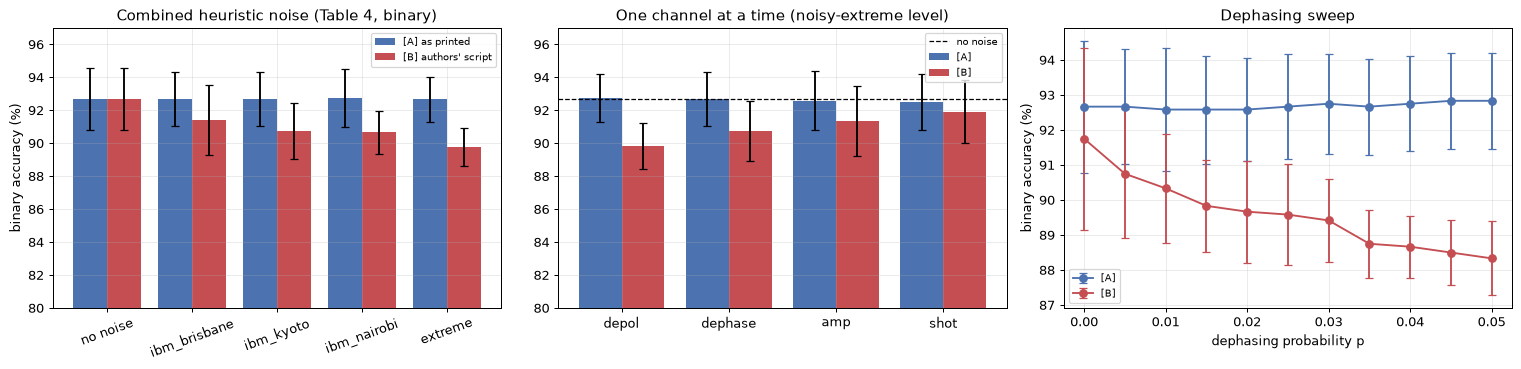

In [20]:
def svm_acc(Ktr, Kte, ytr, yte):
    return 100 * accuracy_score(yte, SVC(kernel="precomputed", C=1.0).fit(Ktr, ytr).predict(Kte))

P_SWEEP = np.linspace(0, 0.05, 11)
VARIANTS = {"A": False, "B": True}          # A = formulas as printed in the paper; B = authors' script (diagonal of the test kernel set to 1)
base_b, base_m = [], []
scen_b = {v: {k: [] for k in BACKEND_NOISE} for v in VARIANTS}; scen_m = {v: {k: [] for k in BACKEND_NOISE} for v in VARIANTS}
single = {v: {c: [] for c in ("depol", "dephase", "amp", "shot")} for v in VARIANTS}
sweep = {v: {p: [] for p in P_SWEEP} for v in VARIANTS}
for rep in range(R_NOISE):
    seed = SEED + 200 + rep
    S = make_qml_sample(seed, n_per_class=N_PER_CLASS_NOISE)
    Ktr, Kte = qkernel(S["Xtr"]), qkernel(S["Xte"], S["Xtr"])
    base_b.append(svm_acc(Ktr, Kte, S["yb_tr"], S["yb_te"])); base_m.append(svm_acc(Ktr, Kte, S["ym_tr"], S["ym_te"]))
    rng = np.random.default_rng(seed)
    for v, quirk in VARIANTS.items():
        for k, par in BACKEND_NOISE.items():
            Kn_tr, Kn_te = apply_noise(Ktr, par, rng, True, quirk=quirk), apply_noise(Kte, par, rng, False, quirk=quirk)
            scen_b[v][k].append(svm_acc(Kn_tr, Kn_te, S["yb_tr"], S["yb_te"])); scen_m[v][k].append(svm_acc(Kn_tr, Kn_te, S["ym_tr"], S["ym_te"]))
        for c in single[v]:
            par = BACKEND_NOISE["Noisy extreme"]
            Kn_tr, Kn_te = apply_noise(Ktr, par, rng, True, only=c, quirk=quirk), apply_noise(Kte, par, rng, False, only=c, quirk=quirk)
            single[v][c].append(svm_acc(Kn_tr, Kn_te, S["yb_tr"], S["yb_te"]))
        for p in P_SWEEP:
            sweep[v][p].append(svm_acc(finish(ch_dephase(Ktr, p), True), finish(ch_dephase(Kte, p), False, authors_quirk=quirk), S["yb_tr"], S["yb_te"]))

mb, sb, mm_, sm = np.mean(base_b), np.std(base_b), np.mean(base_m), np.std(base_m)
rows = [{"Scenario": "No noise", "Acc bin": f"{mb:.2f} +- {sb:.2f}", "delta bin (pp)": "-", "Acc multi": f"{mm_:.2f} +- {sm:.2f}", "delta multi (pp)": "-"}]
for v, label in (("A", "formulas as printed"), ("B", "authors' script")):
    for k in BACKEND_NOISE:
        rows.append({"Scenario": f"[{v}] {k}", "Acc bin": f"{np.mean(scen_b[v][k]):.2f} +- {np.std(scen_b[v][k]):.2f}", "delta bin (pp)": f"{np.mean(scen_b[v][k]) - mb:+.2f}",
                     "Acc multi": f"{np.mean(scen_m[v][k]):.2f} +- {np.std(scen_m[v][k]):.2f}", "delta multi (pp)": f"{np.mean(scen_m[v][k]) - mm_:+.2f}"})
table4 = pd.DataFrame(rows).set_index("Scenario"); display(table4)
for v, label in (("A", "formulas as printed"), ("B", "authors' script")):
    print(f"[{v}] single channels at the 'noisy extreme' level, {label} (binary accuracy, change vs no noise):")
    for c, vals in single[v].items():
        print(f"    {c:8s} {np.mean(vals):6.2f} +- {np.std(vals):4.2f}   ({np.mean(vals) - mb:+.2f} pp)")
p_last = P_SWEEP[-1]
deph_p05 = {v: (np.mean(sweep[v][p_last]), np.std(sweep[v][p_last])) for v in VARIANTS}
for v in VARIANTS:
    print(f"[{v}] dephasing p = {p_last:.2f}: {deph_p05[v][0]:.2f} +- {deph_p05[v][1]:.2f} %  ({deph_p05[v][0] - mb:+.2f} pp vs baseline)")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ks = list(BACKEND_NOISE); xs = np.arange(len(ks) + 1); labels = ["no noise"] + [k.split(" ")[0] if "extreme" not in k else "extreme" for k in ks]
for off, v, col in ((-0.2, "A", "#4c72b0"), (0.2, "B", "#c44e52")):
    ax[0].bar(xs + off, [mb] + [np.mean(scen_b[v][k]) for k in ks], 0.4, yerr=[sb] + [np.std(scen_b[v][k]) for k in ks], label=f"[{v}] " + ("as printed" if v == "A" else "authors' script"), color=col, capsize=3)
ax[0].set_xticks(xs); ax[0].set_xticklabels(labels, rotation=20); ax[0].set_ylim(80, 97)
ax[0].set_ylabel("binary accuracy (%)"); ax[0].set_title("Combined heuristic noise (Table 4, binary)"); ax[0].legend(fontsize=8)
w = 0.4; cs = list(single["A"]); x2 = np.arange(len(cs))
for off, v, col in ((-0.2, "A", "#4c72b0"), (0.2, "B", "#c44e52")):
    ax[1].bar(x2 + off, [np.mean(single[v][c]) for c in cs], w, yerr=[np.std(single[v][c]) for c in cs], color=col, capsize=3, label=f"[{v}]")
ax[1].set_xticks(x2); ax[1].set_xticklabels(cs); ax[1].axhline(mb, c="k", ls="--", lw=1, label="no noise"); ax[1].set_ylim(80, 97)
ax[1].set_title("One channel at a time (noisy-extreme level)"); ax[1].legend(fontsize=8)
for v, col in (("A", "#4c72b0"), ("B", "#c44e52")):
    ax[2].errorbar(P_SWEEP, [np.mean(sweep[v][p]) for p in P_SWEEP], yerr=[np.std(sweep[v][p]) for p in P_SWEEP], marker="o", capsize=3, color=col, label=f"[{v}]")
ax[2].set_xlabel("dephasing probability p"); ax[2].set_ylabel("binary accuracy (%)"); ax[2].set_title("Dephasing sweep"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Circuit-level NISQ noise with Qiskit fake backends (added; not part of the paper)

The paper's noise is a heuristic on the kernel matrix. Here the kernel entries are *measured* from the circuit `U(y)^dagger U(x)` of section 4 after transpilation to the device
(basis gates, a lowest-error 6-qubit chain, routing where needed) on Aer with the noise model of the fake devices FakeBrisbane, FakeSherbrooke (stand-in for ibm_kyoto: the stored FakeKyoto calibration is degenerate, see the printout in section 4) and FakeNairobiV2
(gate errors, thermal relaxation, readout errors) and a finite number of shots. Density-matrix simulation of every pair is slow, so only a few dozen flows are used and the
result is a qualitative cross-check of the paper's claim that NISQ noise degrades the kernel classifier by a few points, not a replication of Table 4.
We compare, on the same flows: the exact kernel, the exact kernel with only shot noise, and the noisy circuit kernel for each device.
Because the diagonal `K(x,x)` is also measured, noise shows up as a diagonal below 1 and a flatter off-diagonal.

  rep 0 ibm_brisbane: 30 train / 18 test flows, 162 s


  rep 0 ibm_sherbrooke: 30 train / 18 test flows, 131 s


  rep 0 ibm_nairobi: 30 train / 18 test flows, 67 s


  rep 1 ibm_brisbane: 30 train / 18 test flows, 241 s


  rep 1 ibm_sherbrooke: 30 train / 18 test flows, 194 s


  rep 1 ibm_nairobi: 30 train / 18 test flows, 101 s
circuit-level study: 898 s; 30 training and 18 test flows per repetition, 4096 shots


,acc_bin,acc_multi,mean_diag,mean_abs_dK,corr_with_exact,seconds
backend,,,,,,
exact kernel,91.667,69.444,1.000,0.000,1.000,0.000
exact + shots (4096),91.667,69.444,1.000,0.001,1.000,0.000
ibm_brisbane,91.667,69.444,0.642,0.031,0.998,201.678
ibm_sherbrooke,91.667,72.222,0.588,0.034,0.996,162.734
ibm_nairobi,91.667,69.444,0.529,0.039,0.990,84.078


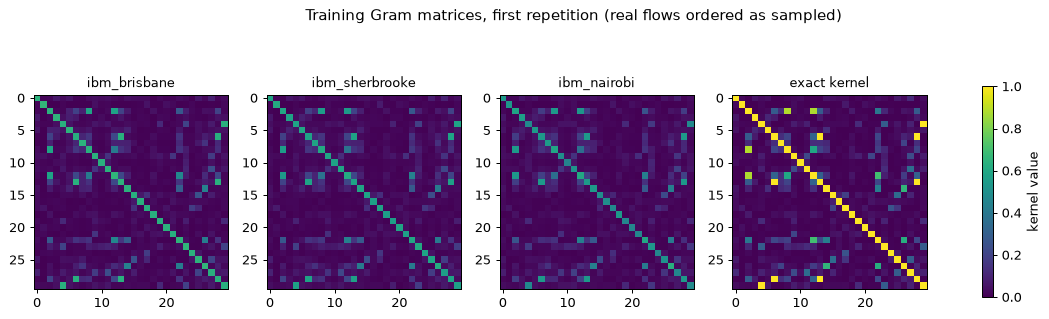

In [21]:
def circuit_kernel_entries(name, pairs_a, pairs_b, shots, seed):
    """Measured P(0...0) of U(y)^dagger U(x) for every row pair (a_i, b_i), on the noisy fake backend."""
    sim = AerSimulator(noise_model=NOISE_MODELS[name], seed_simulator=seed, method="density_matrix")
    tc = TRANSPILED[name]
    out = np.zeros(len(pairs_a))
    for s in range(0, len(pairs_a), 60):                                  # chunks keep memory small
        a, b = pairs_a[s:s + 60], pairs_b[s:s + 60]
        binds = {p: list(a[:, i]) for i, p in enumerate(XPARAMS)}
        binds.update({p: list(b[:, i]) for i, p in enumerate(YPARAMS)})
        res = sim.run(tc, parameter_binds=[binds], shots=shots).result()
        cs = res.get_counts()
        cs = [cs] if isinstance(cs, dict) else cs
        out[s:s + 60] = [c.get("0" * N, 0) / shots for c in cs]
    return out

def noisy_kernels(name, Xtr, Xte, shots, seed):
    n, m = len(Xtr), len(Xte)
    iu = np.triu_indices(n)                                                # train Gram: upper triangle incl. diagonal
    v = circuit_kernel_entries(name, Xtr[iu[0]], Xtr[iu[1]], shots, seed)
    Ktr = np.zeros((n, n)); Ktr[iu] = v; Ktr = Ktr + Ktr.T - np.diag(np.diag(Ktr))
    ti, tj = np.meshgrid(np.arange(m), np.arange(n), indexing="ij")
    Kte = circuit_kernel_entries(name, Xte[ti.ravel()], Xtr[tj.ravel()], shots, seed + 1).reshape(m, n)
    return Ktr, Kte

fake_rows, fake_keep = [], {}
t_all = time.time()
for rep in range(FAKE_REPS):
    seed = SEED + 300 + rep
    full = make_qml_sample(seed, n_per_class=FAKE_PER_CLASS_TRAIN + FAKE_PER_CLASS_TEST, test_size=FAKE_PER_CLASS_TEST / (FAKE_PER_CLASS_TRAIN + FAKE_PER_CLASS_TEST))
    Xtr, Xte, ybtr, ybte, ymtr, ymte = full["Xtr"], full["Xte"], full["yb_tr"], full["yb_te"], full["ym_tr"], full["ym_te"]
    Ktr0, Kte0 = qkernel(Xtr), qkernel(Xte, Xtr)
    rng = np.random.default_rng(seed)
    ideal = (svm_acc(Ktr0, Kte0, ybtr, ybte), svm_acc(Ktr0, Kte0, ymtr, ymte))
    Ks_tr = finish(ch_shot(Ktr0, FAKE_SHOTS, rng), True); Ks_te = finish(ch_shot(Kte0, FAKE_SHOTS, rng), False)
    shot_only = (svm_acc(Ks_tr, Ks_te, ybtr, ybte), svm_acc(Ks_tr, Ks_te, ymtr, ymte))
    fake_rows.append(dict(rep=rep, backend="exact kernel", acc_bin=ideal[0], acc_multi=ideal[1], diag=1.0, mean_abs_dK=0.0, corr=1.0, seconds=0.0))
    fake_rows.append(dict(rep=rep, backend=f"exact + shots ({FAKE_SHOTS})", acc_bin=shot_only[0], acc_multi=shot_only[1], diag=1.0,
                          mean_abs_dK=float(np.abs(Ks_tr - Ktr0).mean()), corr=float(np.corrcoef(Ks_tr.ravel(), Ktr0.ravel())[0, 1]), seconds=0.0))
    for name in FAKE_BACKENDS:
        t0 = time.time()
        Ktr, Kte = noisy_kernels(name, Xtr, Xte, FAKE_SHOTS, seed)
        Ktr = (Ktr + Ktr.T) / 2                                            # no extra clean-up: measured diagonal is kept
        dt = time.time() - t0
        fake_rows.append(dict(rep=rep, backend=name, acc_bin=svm_acc(Ktr, Kte, ybtr, ybte), acc_multi=svm_acc(Ktr, Kte, ymtr, ymte),
                              diag=float(np.mean(np.diag(Ktr))), mean_abs_dK=float(np.abs(Ktr - Ktr0).mean()),
                              corr=float(np.corrcoef(Ktr.ravel(), Ktr0.ravel())[0, 1]), seconds=dt))
        if rep == 0: fake_keep[name] = Ktr
        print(f"  rep {rep} {name}: {len(Xtr)} train / {len(Xte)} test flows, {dt:.0f} s")
    if rep == 0: fake_keep["exact kernel"] = Ktr0
FK = pd.DataFrame(fake_rows)
print(f"circuit-level study: {time.time()-t_all:.0f} s; {len(Xtr)} training and {len(Xte)} test flows per repetition, {FAKE_SHOTS} shots")
fk_tab = FK.groupby("backend", sort=False).agg(acc_bin=("acc_bin", "mean"), acc_multi=("acc_multi", "mean"), mean_diag=("diag", "mean"),
                                               mean_abs_dK=("mean_abs_dK", "mean"), corr_with_exact=("corr", "mean"), seconds=("seconds", "mean")).round(3)
display(fk_tab)

names = list(fake_keep)
fig, ax = plt.subplots(1, len(names), figsize=(4 * len(names), 3.8))
for a, nm in zip(np.atleast_1d(ax), names):
    im = a.imshow(fake_keep[nm], vmin=0, vmax=1, cmap="viridis"); a.set_title(nm, fontsize=10); a.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="kernel value"); plt.suptitle("Training Gram matrices, first repetition (real flows ordered as sampled)", y=1.03); plt.show()

## 9. Side by side with the paper

Rule (from the project brief): a number is *reproduced* when it lies within 2 percentage points (accuracy / F1) of the paper's value, otherwise *not reached* (we are lower) or *exceeded* (we are higher);
claims that cannot be tested here are marked *cannot be checked*.

In [22]:
def verdict(paper, got, tol=2.0):
    if got is None or (isinstance(got, float) and np.isnan(got)): return "cannot be checked"
    if abs(got - paper) <= tol: return "reproduced"
    return ("exceeded" if got > paper else "not reached") + f" ({got - paper:+.1f})"

def cell(model, task, col):
    x = R[(R.model == model) & (R.task == task)][col]
    return float(x.mean()), float(x.std(ddof=0))

claims = []
def add(src, claim, paper, got, tol=2.0, fmt="{:.1f}"):
    claims.append({"Source": src, "Claim": claim, "Paper": fmt.format(paper) if isinstance(paper, (int, float)) else paper,
                   "Notebook": fmt.format(got) if isinstance(got, (int, float)) else got,
                   "Verdict": verdict(paper, got, tol) if isinstance(paper, (int, float)) and isinstance(got, (int, float)) else got})

# Table 2
T2 = {"Decision Tree": (94.58, 94.65, 96.67, 98.02), "Random Forest": (94.92, 94.99, 96.97, 98.21), "Gradient Boosting": (94.67, 94.73, 96.54, 97.95),
      "Logistic Regression": (80.68, 80.69, 93.85, 96.43), "KNN (k=5)": (93.58, 93.66, 96.20, 97.74)}
for m, (a, f, ab, fb) in T2.items():
    mine = table2.loc[m, ["Acc", "F1-macro", "Acc bin", "F1 bin"]].to_numpy(float)
    gap = float(np.max(np.abs(mine - np.array([a, f, ab, fb]))))
    note = "" if CLASSICAL_PER_CLASS == 20_000 else " [5k/class FAST sample]"
    claims.append({"Source": "Table 2", "Claim": f"{m}: Acc / F1-macro / Acc bin / F1 bin", "Paper": f"{a} / {f} / {ab} / {fb}",
                   "Notebook": " / ".join(f"{v:.2f}" for v in mine) + note,
                   "Verdict": "reproduced" if gap <= 2 else f"not reached/exceeded (max gap {gap:.1f})"})
claims.append({"Source": "Table 2", "Claim": "Random Forest has the best F1-macro", "Paper": "yes (94.99)", "Notebook": f"best = {table2['F1-macro'].idxmax()}",
               "Verdict": "reproduced" if table2["F1-macro"].idxmax() == "Random Forest" else "not reached"})
# Table 3
for model, task, pa_, pf_ in (("QKSVM", "binary", 93.9, 87.1), ("VQC", "binary", 67.1, 57.4), ("QIK-SVM", "multi", 84.5, 84.4), ("SVM-RBF", "binary", 93.0, 84.9),
                              ("RF", "multi", 89.2, 89.2), ("LR", "binary", 92.4, 84.5), ("Majority", "binary", 83.3, 45.4), ("Majority", "multi", 16.5, 4.7)):
    a, sa = cell(model, task, "acc"); f, sf = cell(model, task, "f1_macro")
    add("Table 3", f"{model} ({task}) accuracy", pa_, a); add("Table 3", f"{model} ({task}) F1-macro", pf_, f)
claims.append({"Source": "Sec. 4.2", "Claim": "QKSVM > SVM-RBF in all 10 resamplings", "Paper": "10/10", "Notebook": f"{wins}/{len(gain)}",
               "Verdict": "reproduced" if wins == len(gain) == 10 else "not reached"})
add("Sec. 4.2", "mean accuracy gain QKSVM - SVM-RBF (pp)", 0.85, float(gain.mean()), tol=0.5, fmt="{:.2f}")
claims.append({"Source": "Sec. 4.2", "Claim": "VQC does not converge and is below the majority baseline", "Paper": "5/5 runs, 67.1 < 83.3",
               "Notebook": f"success flag in {sum(d['success'] for d in vqc_log)}/{len(vqc_log)}; below baseline in {int((vqc_acc < maj_bin - 1e-9).sum())}/{len(vqc_acc)}",
               "Verdict": "reproduced" if (not any(d['success'] for d in vqc_log)) and bool((vqc_acc < maj_bin).all()) else "partly: see VQC table"})
# learning curve
c30 = (np.mean(curve[30]["qk"]), np.mean(curve[30]["rbf"]))
add("Sec. 4.2", "N=30 QKSVM accuracy", 93.2, c30[0]); add("Sec. 4.2", "N=30 SVM-RBF accuracy", 89.7, c30[1])
claims.append({"Source": "Sec. 4.2", "Claim": "gap QKSVM - RBF below 0.3 pp at N=80", "Paper": "< 0.3 pp",
               "Notebook": f"{np.mean(curve[80]['qk']) - np.mean(curve[80]['rbf']):+.2f} pp",
               "Verdict": "reproduced" if abs(np.mean(curve[80]['qk']) - np.mean(curve[80]['rbf'])) < 0.3 else "not reached"})
claims.append({"Source": "Sec. 4.2", "Claim": "SVM-RBF slightly ahead at N=120", "Paper": "RBF > QKSVM",
               "Notebook": f"{np.mean(curve[120]['qk']) - np.mean(curve[120]['rbf']):+.2f} pp (QKSVM - RBF)",
               "Verdict": "reproduced" if np.mean(curve[120]['rbf']) > np.mean(curve[120]['qk']) else "not reached"})
claims.append({"Source": "Sec. 4.2", "Claim": "QKSVM more stable (smaller std) than RBF at N=30", "Paper": "0.7 vs 4.3",
               "Notebook": f"{np.std(curve[30]['qk']):.1f} vs {np.std(curve[30]['rbf']):.1f}",
               "Verdict": "reproduced" if np.std(curve[30]['qk']) < np.std(curve[30]['rbf']) else "not reached"})
# noise: both variants (A = formulas as printed, B = authors' script with the test-kernel diagonal set to 1)
add("Sec. 5", "noise baseline binary (no noise)", 93.08, mb, fmt="{:.2f}"); add("Sec. 5", "noise baseline six-class (no noise)", 82.33, mm_, fmt="{:.2f}")
T4 = {"ibm_brisbane (2024)": (91.50, 80.25), "ibm_kyoto (2023)": (90.92, 78.75), "ibm_nairobi (2022)": (90.50, 78.33), "Noisy extreme": (89.83, 76.00)}
for v, tag in (("A", "[A] formulas as printed"), ("B", "[B] authors' script")):
    for k, (pbn, pml) in T4.items():
        add("Table 4", f"{tag}: {k} binary accuracy", pbn, float(np.mean(scen_b[v][k])), fmt="{:.2f}")
        add("Table 4", f"{tag}: {k} six-class accuracy", pml, float(np.mean(scen_m[v][k])), fmt="{:.2f}")
    db = [mb - np.mean(scen_b[v][k]) for k in BACKEND_NOISE]
    claims.append({"Source": "Sec. 5", "Claim": f"{tag}: binary degradation range 1.58 to 3.25 pp", "Paper": "1.58 - 3.25",
                   "Notebook": f"{min(db):.2f} - {max(db):.2f}", "Verdict": "reproduced" if min(db) >= 0.58 and max(db) <= 4.25 else "not reached (no/too small degradation)"})
    claims.append({"Source": "Sec. 5", "Claim": f"{tag}: degradation ordered brisbane < kyoto < nairobi < extreme", "Paper": "yes (within 1 std)",
                   "Notebook": ", ".join(f"{d:.2f}" for d in db), "Verdict": "reproduced" if db == sorted(db) and max(db) > 0.5 else "not reproduced"})
    add("Sec. 5", f"{tag}: dephasing p=0.05 binary accuracy", 87.75, deph_p05[v][0], fmt="{:.2f}")
    worst = min(single[v], key=lambda c: np.mean(single[v][c]))
    claims.append({"Source": "Sec. 5", "Claim": f"{tag}: dephasing is the most damaging single channel", "Paper": "yes",
                   "Notebook": "drops: " + ", ".join(f"{c} {np.mean(single[v][c]) - mb:+.2f}" for c in single[v]),
                   "Verdict": "reproduced" if (worst == "dephase" and mb - np.mean(single[v][worst]) > 0.5) else "not reproduced"})
claims.append({"Source": "Sec. 5.1", "Claim": "near-RT RIC latency / xApp viability", "Paper": "not measured", "Notebook": "not measured", "Verdict": "cannot be checked"})
claims.append({"Source": "added", "Claim": "circuit-level fake-backend noise lowers accuracy vs exact kernel", "Paper": "(not in paper)",
               "Notebook": "; ".join(f"{r.Index}: bin {r.acc_bin:.1f}" for r in fk_tab.itertuples()), "Verdict": "informational (tiny sample)"})
final = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 80, "display.width", 250)
display(final)
vc = final["Verdict"].str.extract(r"^(reproduced|exceeded|not reached|not reproduced|cannot be checked|informational|partly)", expand=False).fillna("other").value_counts()
print(vc.to_string())

,Source,Claim,Paper,Notebook,Verdict
0,Table 2,Decision Tree: Acc / F1-macro / Acc bin / F1 bin,94.58 / 94.65 / 96.67 / 98.02,94.50 / 94.57 / 96.60 / 97.98,reproduced
1,Table 2,Random Forest: Acc / F1-macro / Acc bin / F1 bin,94.92 / 94.99 / 96.97 / 98.21,94.76 / 94.84 / 96.93 / 98.18,reproduced
2,Table 2,Gradient Boosting: Acc / F1-macro / Acc bin / F1 bin,94.67 / 94.73 / 96.54 / 97.95,94.59 / 94.66 / 96.45 / 97.89,reproduced
3,Table 2,Logistic Regression: Acc / F1-macro / Acc bin / F1 bin,80.68 / 80.69 / 93.85 / 96.43,80.56 / 80.54 / 93.81 / 96.41,reproduced
4,Table 2,KNN (k=5): Acc / F1-macro / Acc bin / F1 bin,93.58 / 93.66 / 96.2 / 97.74,93.53 / 93.62 / 96.20 / 97.73,reproduced
5,Table 2,Random Forest has the best F1-macro,yes (94.99),best = Random Forest,reproduced
6,Table 3,QKSVM (binary) accuracy,93.9,94.0,reproduced
7,Table 3,QKSVM (binary) F1-macro,87.1,87.6,reproduced
8,Table 3,VQC (binary) accuracy,67.1,68.4,reproduced
9,Table 3,VQC (binary) F1-macro,57.4,57.5,reproduced


Verdict
reproduced           42
exceeded              6
not reached           5
not reproduced        3
cannot be checked     1
informational         1


## 10. Reading the paper critically

* **Small differences, small samples.** The headline claim is that the ZZ quantum kernel beats SVM-RBF in 10 of 10 resamplings by 0.85 pp. On 375 test flows one flow is 0.27 pp, so the whole gain is about three flows; the resamplings share the same 120,000-flow pool, so they are not independent. The paper itself says this is "a small but consistent advantage" and not general superiority.
* **The classical comparison is weak.** SVM-RBF uses scikit-learn defaults on features that are mostly heavy-tailed (`duration`, `dst_port`) squeezed into [0, pi] by min-max scaling, with no tuning of `C` or `gamma`. The quantum kernel has the same untuned `C`. Section 5 of this notebook adds a quantum kernel with a bandwidth chosen on validation data, and the random forest on the same six features, to show how the picture changes with a fairer tuning protocol.
* **Majority baseline.** With 83.3 % attacks in the test set, binary accuracies of 93 % are only about 10 points above the trivial classifier; F1-macro (87 % vs 85 %) is the more informative column. The VQC "below the baseline" result is therefore less a statement about quantum learning than about an under-trained 24-parameter model (100 training flows, 100 COBYLA evaluations).
* **Possible leakage.** `src_port` is an ephemeral port in most flows and `dst_port` identifies the attacked service; a testbed in which each attack was launched from one tool and one target can make these ports a shortcut that will not hold in a real network. The authors also fit the min-max scaler on the whole sample; here it is fitted on the training split. In addition, 15,381 of the 120,000 rows (12.8 %) are exact duplicates of another row (section 1), so identical flows can land in both the training and the test split of a resampling, which favours memorising methods such as random forests and kernel machines with narrow kernels.
* **Noise is not simulated, and Table 4 is an implementation artefact.** The four channels are scalar maps on the kernel entries (`a K + (1-a)/2^n`, `exp(-p d) K`, ...), not the action of noise on the circuit. Worse, such affine maps hardly change an SVM trained on the noisy Gram matrix: applied exactly as printed (variant A of section 7) the accuracy does not move at all, whatever the backend or dephasing probability. The degradation of 1.6-3.3 pp (and the dephasing result) appears only when the diagonal of the *rectangular test kernel* is also overwritten with ones, as the authors' public script does (variant B): that declares test flow i and training flow i identical, which is label noise injected by the code, not decoherence. The qualitative statement that NISQ noise degrades the kernel classifier is therefore not supported by that experiment. Section 8 shows what actual device noise does to the 6-qubit, depth-130 kernel circuit: the diagonal of the Gram matrix falls well below 1 (0.5-0.65 here) and off-diagonal entries are perturbed, which is a real but different effect. The heuristic parameters are also "calibrated" without published values, and the ordering of the four scenarios is within one standard deviation.
* **Data availability.** The 1.7 M-flow dataset cannot be downloaded from the NetsLab repository (empty `.db` files), so the feature engineering and the 15-feature selection cannot be audited; only the authors' reduced sample is public. Also, the dataset name suggests O-RAN KPIs but, as the paper admits, it holds ordinary aggregated TCP/UDP/ICMP flows, so nothing here is specific to E2/O1/A1 traffic.
* **Latency.** Statevector simulation of a 6-qubit kernel is fast on a CPU but says nothing about hardware: the quantum kernel needs O(N) kernel evaluations per inference against all support vectors, each with thousands of shots, which does not fit the 10 ms - 1 s near-RT RIC loop on today's queues.

## 11. Exercises

1. **Bandwidth.** Add more angle scales (0.1 ... 4) to `pick_scale`. Is the validation-tuned quantum kernel better than SVM-RBF with a tuned `C` and `gamma` (grid search on the training data only)?
2. **Entanglement and depth.** Rebuild the kernel with `entanglement="full"` and `reps` in {1, 2, 3}. How do the off-diagonal kernel values (concentration) and the accuracy change?
3. **More qubits.** Use the RF top-six features of section 2, or eight features on eight qubits. Does the paired QKSVM-vs-RBF gain survive?
4. **A fair VQC.** Give the VQC more training flows and COBYLA iterations, or use SPSA/Adam with the parameter-shift rule. Can it get above the 83.3 % majority baseline?
5. **Noise.** Replace the heuristic channels in section 7 by the circuit-level kernels of section 8 for a larger sample (`FAKE_PER_CLASS_TRAIN = 10`), or transpile with `optimization_level=3`. How does the diagonal of the noisy Gram matrix scale with circuit depth?